# SIT215 Computational Intelligence
## Assignment 1: Problem Solving

### Wheelchair-Accessible Campus Navigation Using A* and Dijkstra

**Student Name:** Siya Dhamija

**Student ID:** 2510999117

**Unit:** SIT215 Computational Intelligence  

**Assignment:** Assignment 1


In [104]:
import math
import heapq
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [105]:
TOTAL_NODES = 34
TOTAL_PATHS = 42
print("Number of nodes:", TOTAL_NODES)
print("Number of path segments:", TOTAL_PATHS)

Number of nodes: 34
Number of path segments: 42


In [106]:
# CAMPUS NODE INFORMATION

node_names = {
    "N1": "Main Entrance",
    "N2": "Jindal Global Law School",
    "N3": "Jindal Global Business School",
    "N4": "Jindal School of Government and Public Policy",
    "N5": "Jindal School of Art & Architecture",
    "N6": "ICICI Bank Ltd.",
    "N7": "Faculty Block",
    "N8": "Main Campus Junction",
    "N9": "Executive Housing",
    "N10": "Masters' Village",
    "N11": "Campus Location 11",
    "N12": "SH-2 Hostel",
    "N13": "SH-3 Hostel",
    "N14": "SH-10 Hostel Area",
    "N15": "SH-11 Hostel",
    "N16": "Health Centre",
    "N17": "Centre for Wellness",
    "N18": "Sportorium",
    "N19": "Badminton Court",
    "N20": "Basketball Court",
    "N21": "Sports Academy",
    "N22": "Padel Court",
    "N23": "Constitution Museum",
    "N24": "Visitor Parking",
    "N25": "Jindal School of Banking",
    "N26": "Flag Pole",
    "N27": "Academic Block - North",
    "N28": "Arts & Design Block - West",
    "N29": "Subway",
    "N30": "Jindal School of Finance",
    "N31": "Global Auditorium",
    "N32": "Global Library",
    "N33": "Student Common Area",
    "N34": "Jindal School of Environment and Sustainability"
}

print("Total nodes:", len(node_names))

Total nodes: 34


In [107]:
coordinates = {
    "N1":  (100, 100),
    "N2":  (80, 170),
    "N3":  (170, 220),
    "N4":  (250, 280),
    "N5":  (170, 160),
    "N6":  (330, 90),
    "N7":  (420, 220),
    "N8":  (540, 70),
    "N9":  (570, 80),
    "N10": (650, 150),
    "N11": (720, 230),
    "N12": (760, 300),
    "N13": (690, 330),
    "N14": (800, 250),
    "N15": (880, 250),
    "N16": (850, 330),
    "N17": (760, 370),
    "N18": (900, 500),
    "N19": (870, 520),
    "N20": (760, 500),
    "N21": (720, 460),
    "N22": (700, 600),
    "N23": (620, 500),
    "N24": (600, 400),
    "N25": (560, 350),
    "N26": (500, 500),
    "N27": (430, 620),
    "N28": (350, 650),
    "N29": (420, 400),
    "N30": (300, 470),
    "N31": (250, 400),
    "N32": (180, 360),
    "N33": (120, 330),
    "N34": (730, 410)
}

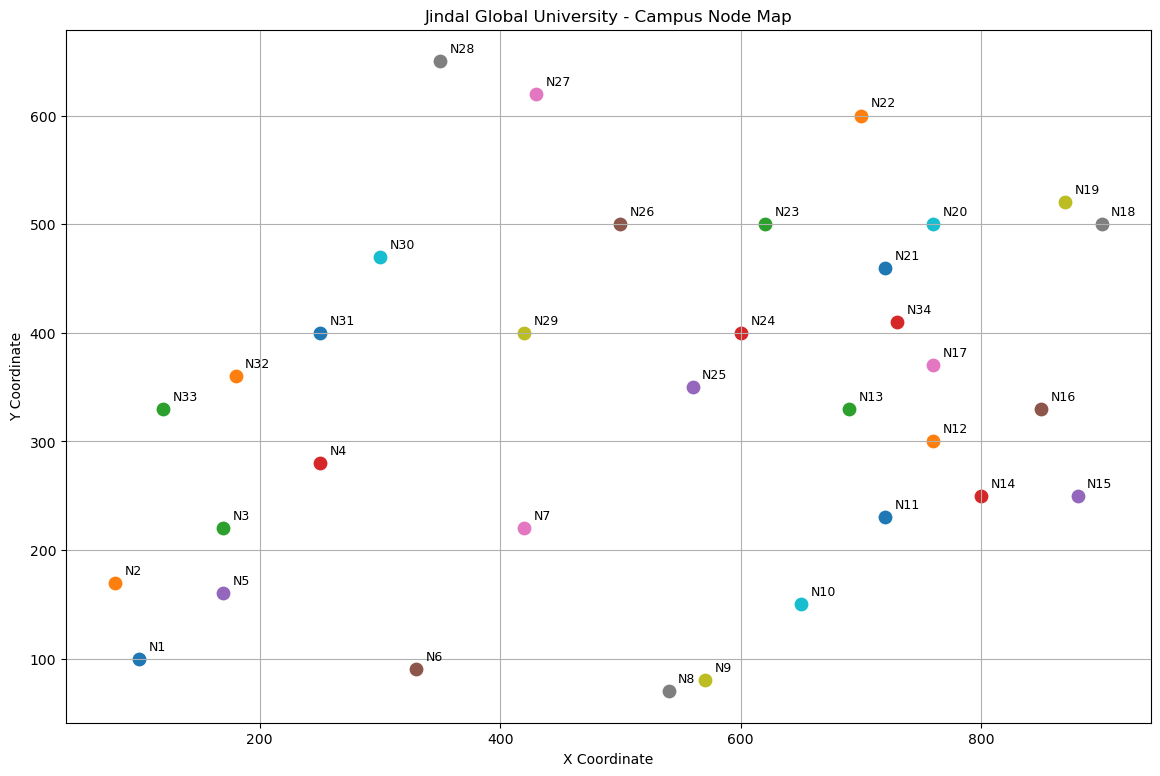

In [108]:
# VISUALISE CAMPUS NODES


plt.figure(figsize=(14, 9))

for node, (x, y) in coordinates.items():
    plt.scatter(x, y, s=80)
    plt.text(x + 8, y + 8, node, fontsize=9)

plt.title("Jindal Global University - Campus Node Map")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.show()

In [109]:
#  CAMPUS PATH CONNECTIONS

connections = [

    ("N1",  "N2",  "P1"),
    ("N6",  "N2",  "P2"),
    ("N5",  "N4",  "P3"),
    ("N3",  "N4",  "P4"),

    ("N3",  "N32", "P5"),
    ("N32", "N10", "P6"),
    ("N31", "N32", "P7"),
    ("N31", "N30", "P8"),
    ("N30", "N29", "P9"),
    ("N32", "N26", "P10"),

    ("N28", "N29", "P11"),
    ("N28", "N25", "P12"),
    ("N29", "N21", "P13"),

    ("N28", "N27", "P14"),
    ("N27", "N23", "P15"),
    ("N27", "N22", "P16"),
    ("N22", "N21", "P17"),

    ("N26", "N24", "P18"),
    ("N26", "N23", "P19"),
    ("N23", "N24", "P20"),

    ("N24", "N25", "P21"),
    ("N20", "N25", "P22"),
    ("N20", "N17", "P23"),
    ("N19", "N20", "P24"),

    ("N19", "N17", "P25"),
    ("N18", "N16", "P26"),
    ("N17", "N15", "P27"),
    ("N21", "N18", "P28"),
    ("N25", "N16", "P29"),
    ("N5",  "N29", "P30"),

    ("N7",  "N25", "P31"),
    ("N7",  "N9",  "P32"),
    ("N7",  "N6",  "P33"),
    ("N7",  "N8",  "P34"),

    ("N10", "N34", "P35"),
    ("N34", "N12", "P36"),
    ("N12", "N14", "P37"),
    ("N13", "N14", "P38"),
    ("N14", "N15", "P39"),

    ("N33", "N3",  "P40"),
    ("N2",  "N3",  "P41"),
    ("N6",  "N7",  "P42")
]

print("Total path connections:", len(connections))

Total path connections: 42


In [110]:

# CREATE PATH DATAFRAME

edges_df = pd.DataFrame(
    connections,
    columns=["From", "To", "Path"]
)

print(edges_df)

print("\nTotal path segments:", len(edges_df))

used_nodes = set(edges_df["From"]) | set(edges_df["To"])

print("Unique nodes used in paths:", len(used_nodes))

# Check which defined nodes are not connected
unused_nodes = set(node_names.keys()) - used_nodes

print("Nodes not currently used in a path:", unused_nodes)

   From   To Path
0    N1   N2   P1
1    N6   N2   P2
2    N5   N4   P3
3    N3   N4   P4
4    N3  N32   P5
5   N32  N10   P6
6   N31  N32   P7
7   N31  N30   P8
8   N30  N29   P9
9   N32  N26  P10
10  N28  N29  P11
11  N28  N25  P12
12  N29  N21  P13
13  N28  N27  P14
14  N27  N23  P15
15  N27  N22  P16
16  N22  N21  P17
17  N26  N24  P18
18  N26  N23  P19
19  N23  N24  P20
20  N24  N25  P21
21  N20  N25  P22
22  N20  N17  P23
23  N19  N20  P24
24  N19  N17  P25
25  N18  N16  P26
26  N17  N15  P27
27  N21  N18  P28
28  N25  N16  P29
29   N5  N29  P30
30   N7  N25  P31
31   N7   N9  P32
32   N7   N6  P33
33   N7   N8  P34
34  N10  N34  P35
35  N34  N12  P36
36  N12  N14  P37
37  N13  N14  P38
38  N14  N15  P39
39  N33   N3  P40
40   N2   N3  P41
41   N6   N7  P42

Total path segments: 42
Unique nodes used in paths: 33
Nodes not currently used in a path: {'N11'}


In [111]:
# CALCULATE PATH DISTANCES


def euclidean_distance(node1, node2):
    x1, y1 = coordinates[node1]
    x2, y2 = coordinates[node2]

    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)


edges_df["Distance"] = edges_df.apply(
    lambda row: euclidean_distance(row["From"], row["To"]),
    axis=1
)

edges_df

,From,To,Path,Distance
0,N1,N2,P1,72.801099
1,N6,N2,P2,262.488095
2,N5,N4,P3,144.222051
3,N3,N4,P4,100.000000
4,N3,N32,P5,140.356688
5,N32,N10,P6,514.781507
6,N31,N32,P7,80.622577
7,N31,N30,P8,86.023253
8,N30,N29,P9,138.924440
9,N32,N26,P10,349.284984


C:\Users\HP\AppData\Local\Temp\ipykernel_8200\1421659281.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


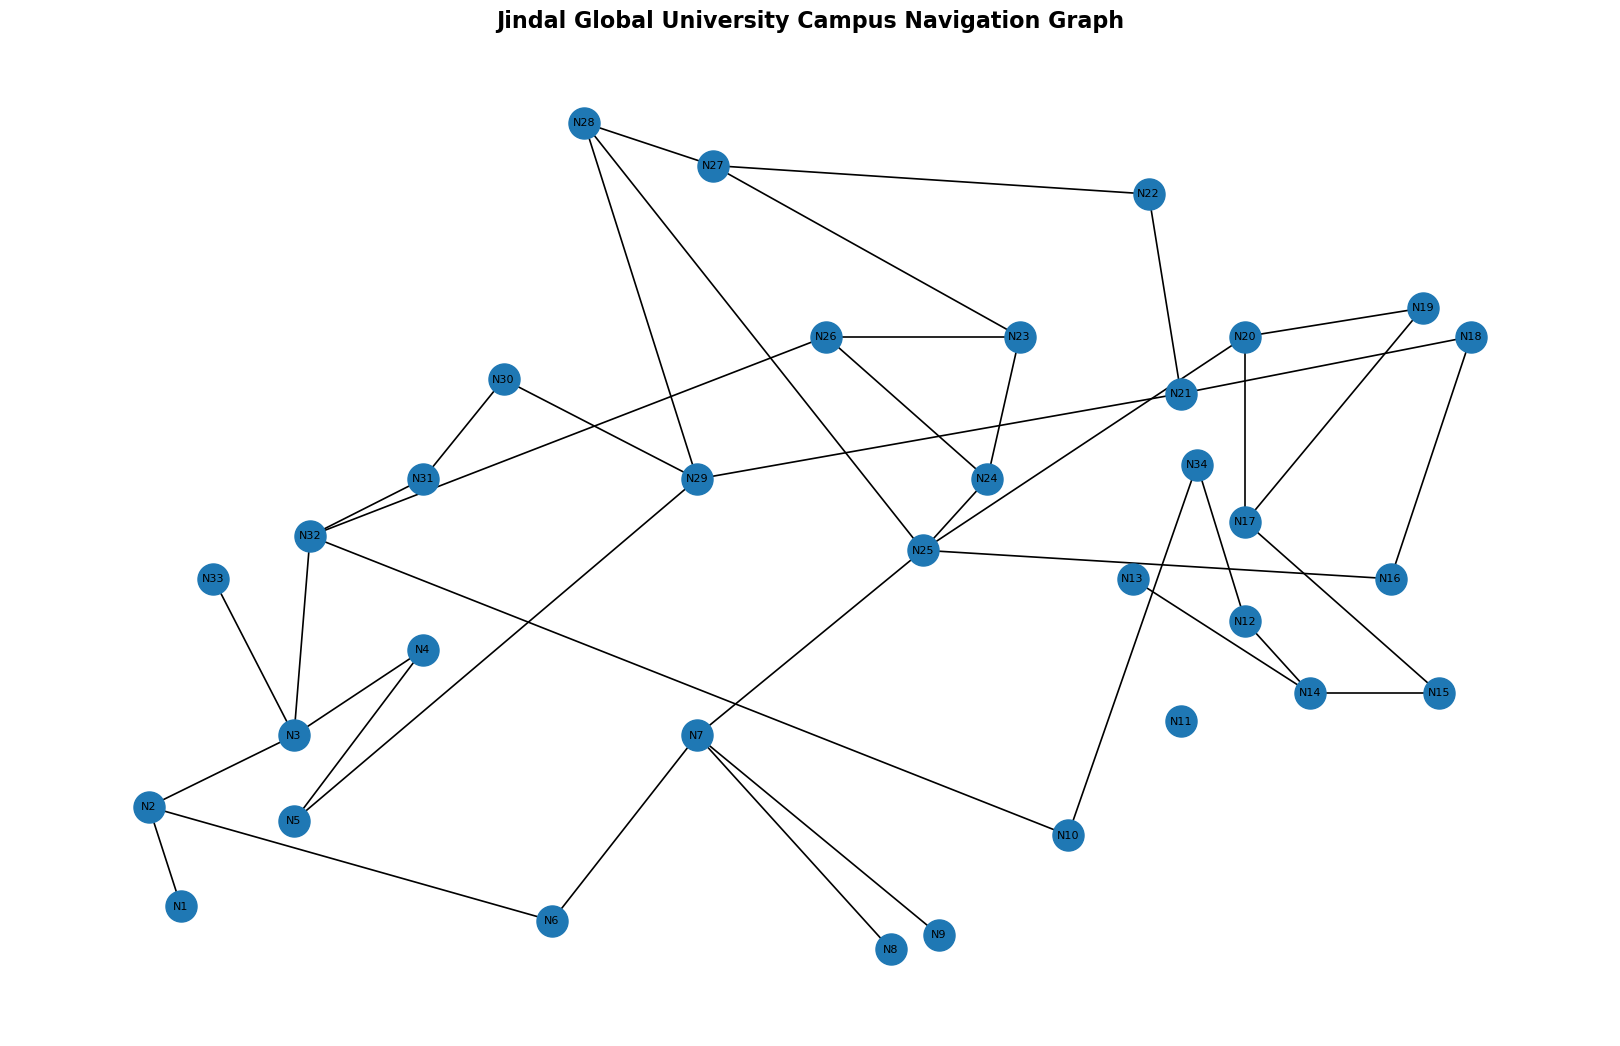

Campus Navigation Graph
Number of nodes: 34
Number of path segments: 41


In [166]:

# TASK 2: CAMPUS NAVIGATION GRAPH

# Create an undirected graph
G = nx.Graph()

for node, (x, y) in coordinates.items():
    G.add_node(
        node,
        pos=(x, y)
    )


# Add all path connections
for _, row in edges_df.iterrows():

    G.add_edge(
        row["From"],
        row["To"],
        weight=row["Distance"],
        path=row["Path"]
    )

pos = {
    node: coordinates[node]
    for node in G.nodes()
}

plt.figure(figsize=(16, 10))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=500,
    font_size=8,
    width=1.2
)

plt.title(
    "Jindal Global University Campus Navigation Graph",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Campus Navigation Graph")
print("Number of nodes:", G.number_of_nodes())
print("Number of path segments:", G.number_of_edges())

In [170]:
# ADJACENCY MATRIX WITH INFINITY FOR NO DIRECT CONNECTION

adjacency_matrix = pd.DataFrame(
    np.inf,
    index=node_names.keys(),
    columns=node_names.keys()
)

# A node has zero cost to itself
np.fill_diagonal(adjacency_matrix.values, 0)

# Add the actual path distances
for _, row in edges_df.iterrows():

    start = row["From"]
    end = row["To"]
    distance = row["Distance"]

    adjacency_matrix.loc[start, end] = distance
    adjacency_matrix.loc[end, start] = distance

print("Weighted Adjacency Matrix:")
display(adjacency_matrix)

print("\nMatrix size:", adjacency_matrix.shape)
print("Number of nodes:", len(adjacency_matrix))

Weighted Adjacency Matrix:


,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,...,N25,N26,N27,N28,N29,N30,N31,N32,N33,N34
N1,0.000000,72.801099,inf,inf,inf,inf,inf,inf,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N2,72.801099,0.000000,102.956301,inf,inf,262.488095,inf,inf,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N3,inf,102.956301,0.000000,100.000000,inf,inf,inf,inf,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,140.356688,120.83046,inf
N4,inf,inf,100.000000,0.000000,144.222051,inf,inf,inf,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N5,inf,inf,inf,144.222051,0.000000,inf,inf,inf,inf,inf,...,inf,inf,inf,inf,346.554469,inf,inf,inf,inf,inf
N6,inf,262.488095,inf,inf,inf,0.000000,158.113883,inf,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N7,inf,inf,inf,inf,inf,158.113883,0.000000,192.093727,205.182845,inf,...,191.049732,inf,inf,inf,inf,inf,inf,inf,inf,inf
N8,inf,inf,inf,inf,inf,inf,192.093727,0.000000,inf,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N9,inf,inf,inf,inf,inf,inf,205.182845,inf,0.000000,inf,...,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf
N10,inf,inf,inf,inf,inf,inf,inf,inf,inf,0.000000,...,inf,inf,inf,inf,inf,inf,inf,514.781507,inf,272.029410



Matrix size: (34, 34)
Number of nodes: 34


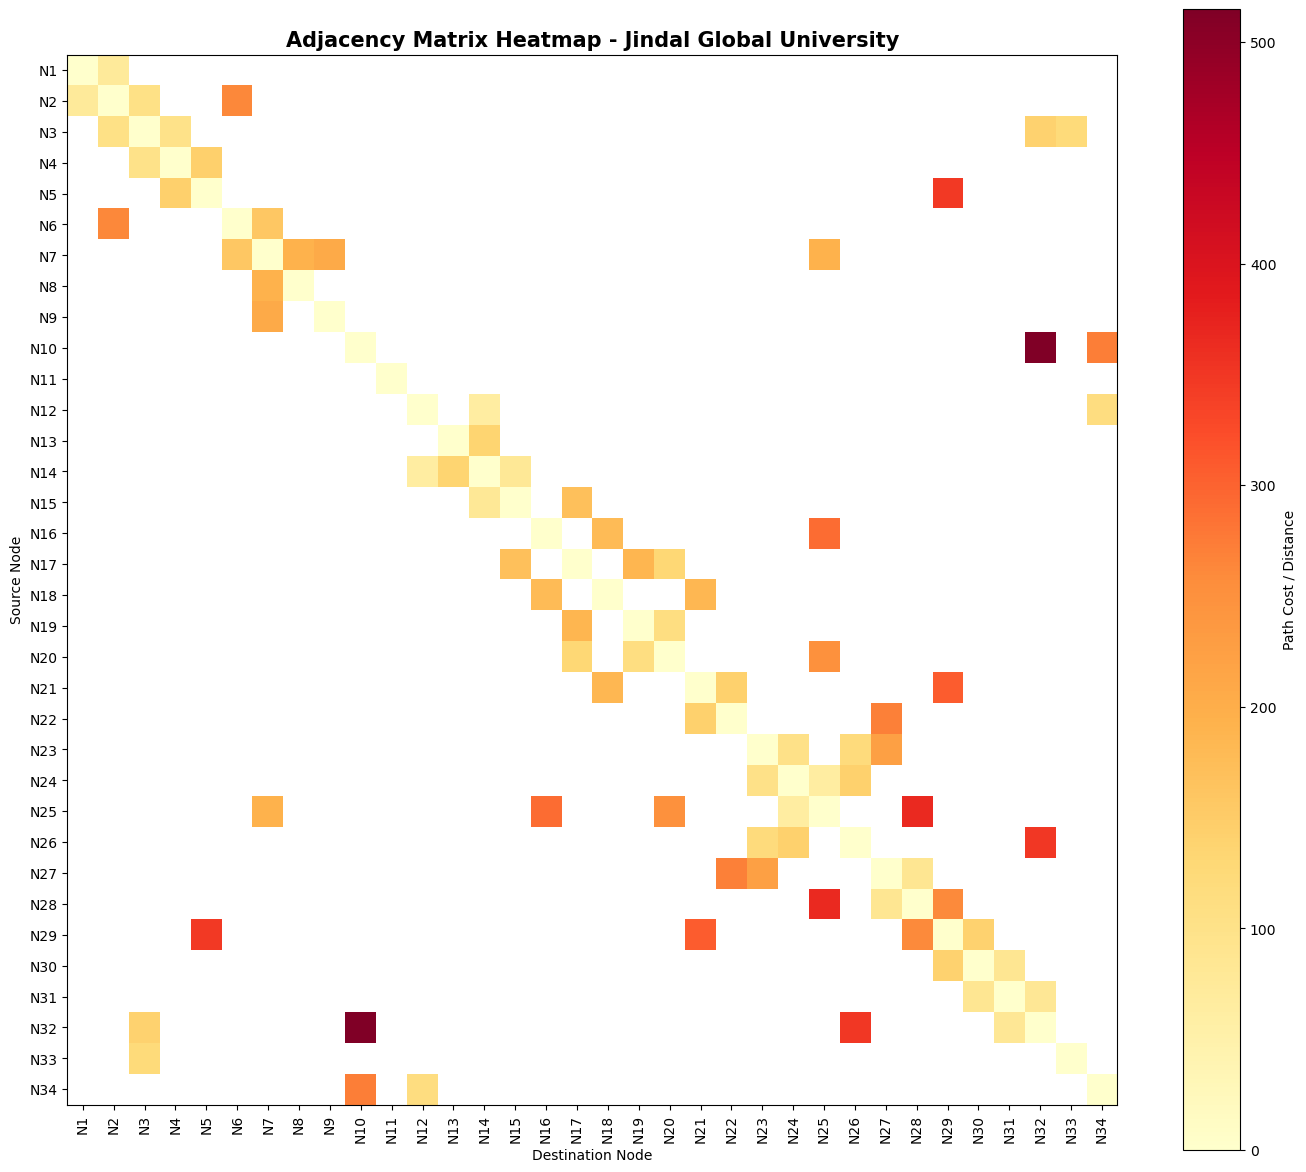

In [169]:
#  ADJACENCY MATRIX HEATMAP


plt.figure(figsize=(14, 12))

plt.imshow(
    adjacency_matrix.values,
    cmap="YlOrRd",
    interpolation="nearest"
)

plt.colorbar(
    label="Path Cost / Distance"
)

plt.xticks(
    range(len(adjacency_matrix.columns)),
    adjacency_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(adjacency_matrix.index)),
    adjacency_matrix.index
)

plt.title(
    "Adjacency Matrix Heatmap - Jindal Global University",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Destination Node")
plt.ylabel("Source Node")

plt.tight_layout()

plt.show()

In [164]:
# TASK 2: TESTING RESULTS

# Different start and goal combinations
test_cases = [
    ("N1", "N34"),
    ("N2", "N20"),
    ("N5", "N18"),
    ("N10", "N28"),
    ("N15", "N3")
]

results = []

# Test A* for every start-goal combination
for start, goal in test_cases:

    # Record starting time
    start_time = time.perf_counter()

    # Run A* using the Euclidean heuristic
    result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    # Record ending time
    end_time = time.perf_counter()

    # Store the testing results
    results.append({
        "Start Node": start,
        "Goal Node": goal,
        "Calculated Path": (
            " → ".join(result["path"])
            if result["path"] is not None
            else "No route found"
        ),
        "Path Cost": result["cost"],
        "Nodes Expanded": result["nodes_expanded"],
        "Execution Time": end_time - start_time
    })

# Convert results into a DataFrame
testing_results_df = pd.DataFrame(results)

display(testing_results_df)

,Start Node,Goal Node,Calculated Path,Path Cost,Nodes Expanded,Execution Time
0,N1,N34,N1 → N2 → N3 → N32 → N10 → N34,1102.925006,22,0.000154
1,N2,N20,N2 → N6 → N7 → N25 → N20,861.651710,12,0.000075
2,N5,N18,N5 → N29 → N21 → N18,836.886529,5,0.000036
3,N10,N28,N10 → N32 → N31 → N30 → N29 → N28,1079.966877,11,0.000055
4,N15,N3,N15 → N14 → N12 → N34 → N10 → N32 → N3,1185.216391,15,0.000068


In [114]:
# ACCESSIBILITY INFORMATION


np.random.seed(42)

edges_df["Slope"] = np.random.choice(
    [0, 1, 2],
    size=len(edges_df),
    p=[0.60, 0.30, 0.10]
)

edges_df["Ramp"] = np.random.choice(
    [0, 1],
    size=len(edges_df),
    p=[0.20, 0.80]
)

edges_df["Obstacle"] = 0

edges_df["AccessibilityPenalty"] = (
    edges_df["Slope"] * 5
    + (1 - edges_df["Ramp"]) * 10
)

edges_df

,From,To,Path,Distance,Slope,Ramp,Obstacle,AccessibilityPenalty
0,N1,N2,P1,72.801099,0,0,0,10
1,N6,N2,P2,262.488095,2,1,0,10
2,N5,N4,P3,144.222051,1,1,0,5
3,N3,N4,P4,100.000000,0,1,0,0
4,N3,N32,P5,140.356688,0,1,0,0
5,N32,N10,P6,514.781507,0,1,0,0
6,N31,N32,P7,80.622577,0,1,0,0
7,N31,N30,P8,86.023253,1,0,0,15
8,N30,N29,P9,138.924440,1,1,0,5
9,N32,N26,P10,349.284984,1,1,0,5


In [115]:

#  CREATE OBSTACLE SCENARIO

edges_no_obstacles = edges_df.copy()

edges_with_obstacles = edges_df.copy()

# Four temporary obstacle locations for experimental testing.

obstacle_paths = [
    "P12",
    "P20",
    "P30",
    "P35"
]

# Mark the selected path segments as obstacles
edges_with_obstacles["Obstacle"] = edges_with_obstacles[
    "Path"
].isin(obstacle_paths).astype(int)

print("No-obstacle environment:")
print("Obstacles =", 0)

print("\nObstacle environment:")
print("Obstacles =", edges_with_obstacles["Obstacle"].sum())

print("\nBlocked path segments:")
print(obstacle_paths)

No-obstacle environment:
Obstacles = 0

Obstacle environment:
Obstacles = 4

Blocked path segments:
['P12', 'P20', 'P30', 'P35']


In [116]:
# CELL 11: CREATE WEIGHTED GRAPH ============================================================

def create_graph(edge_data, include_obstacles=False):

    graph = {node: [] for node in node_names}

    for _, row in edge_data.iterrows():

        # If obstacles are NOT included, skip blocked paths
        if not include_obstacles and row["Obstacle"] == 1:
            continue

        distance = row["Distance"]

        # Add connection in both directions
        graph[row["From"]].append(
            (row["To"], distance)
        )

        graph[row["To"]].append(
            (row["From"], distance)
        )

    return graph

In [117]:
# CELL 12: CREATE NO-OBSTACLE AND OBSTACLE GRAPHS

# Graph where all paths are available
graph_no_obstacles = create_graph(
    edges_no_obstacles,
    include_obstacles=True
)

# Graph where the 4 blocked paths are removed
graph_with_obstacles = create_graph(
    edges_with_obstacles,
    include_obstacles=False
)

print("No-obstacle graph created.")
print("Obstacle graph created.")

print("\nNumber of blocked paths:", len(obstacle_paths))
print("Blocked paths:", obstacle_paths)

No-obstacle graph created.
Obstacle graph created.

Number of blocked paths: 4
Blocked paths: ['P12', 'P20', 'P30', 'P35']


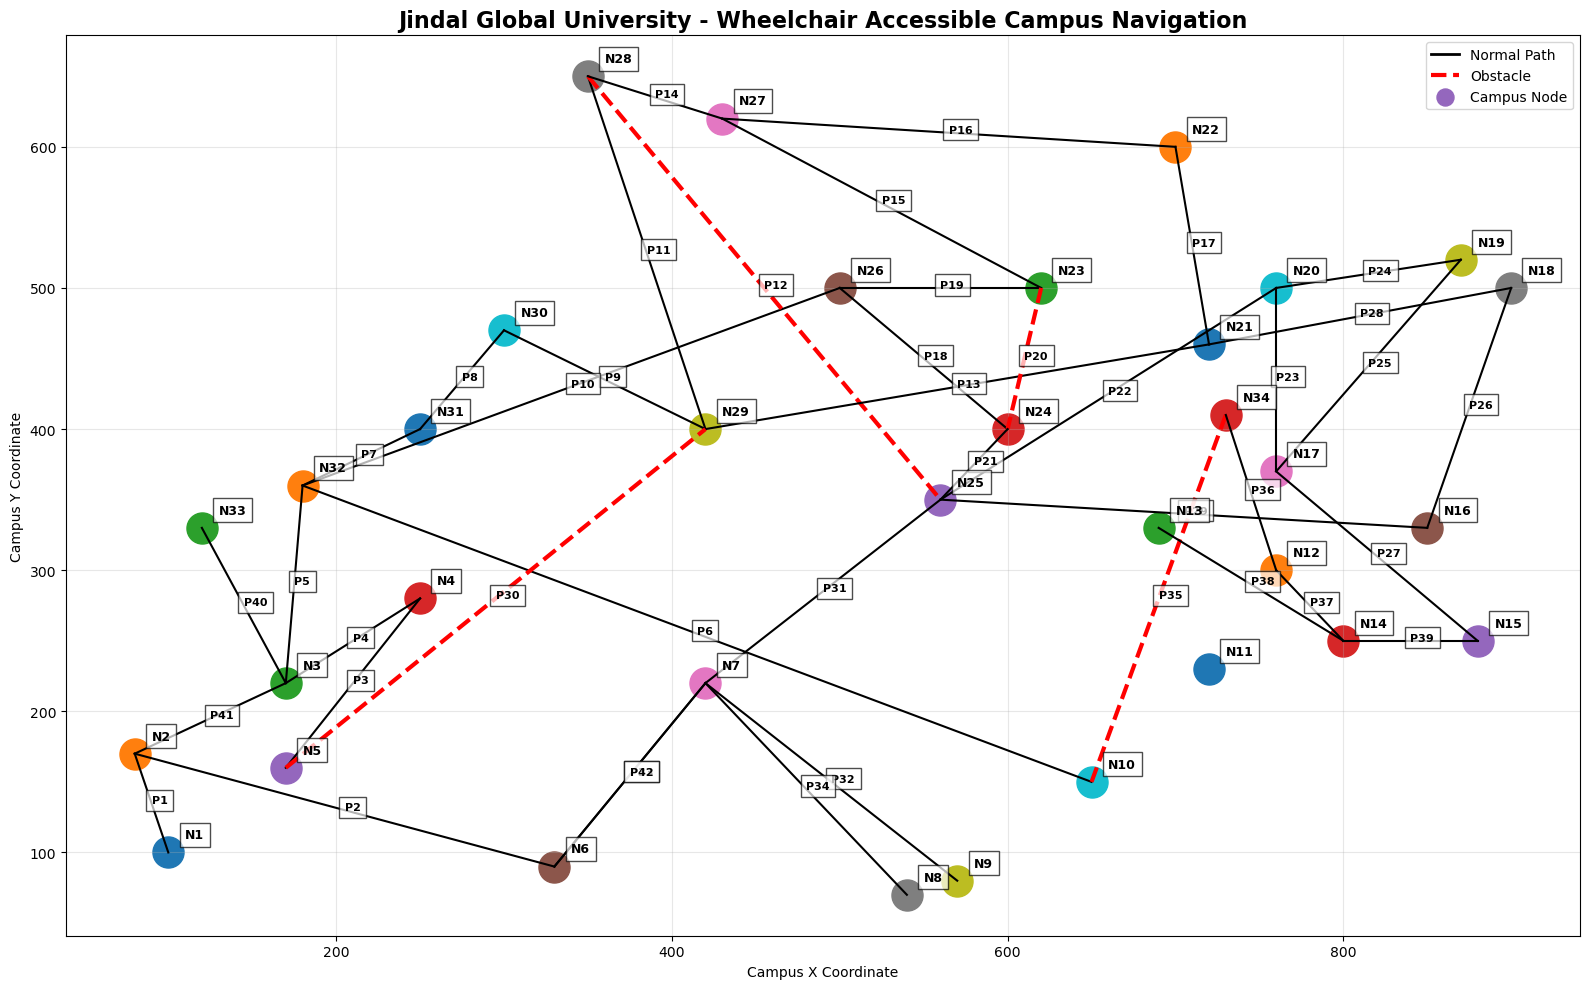

In [162]:

#  CAMPUS GRAPH VISUALISATION

plt.figure(figsize=(16, 10))


for _, row in edges_df.iterrows():

    start = row["From"]
    end = row["To"]
    path_id = row["Path"]

    x1, y1 = coordinates[start]
    x2, y2 = coordinates[end]

    # Check whether this path is an obstacle
    if path_id in obstacle_paths:

        # Obstacle path = red dashed line
        plt.plot(
            [x1, x2],
            [y1, y2],
            "r--",
            linewidth=3
        )

    else:

        # Normal path = black solid line
        plt.plot(
            [x1, x2],
            [y1, y2],
            "black",
            linewidth=1.5
        )

    mid_x = (x1 + x2) / 2
    mid_y = (y1 + y2) / 2

    plt.text(
        mid_x,
        mid_y,
        path_id,
        fontsize=8,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )


for node, (x, y) in coordinates.items():

    # Draw node
    plt.scatter(
        x,
        y,
        s=500,
        marker="o"
    )

    # Node label
    plt.text(
        x + 10,
        y + 10,
        node,
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )



plt.title(
    "Jindal Global University - Wheelchair Accessible Campus Navigation",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Campus X Coordinate")
plt.ylabel("Campus Y Coordinate")


plt.plot(
    [],
    [],
    "black",
    linewidth=2,
    label="Normal Path"
)

plt.plot(
    [],
    [],
    "r--",
    linewidth=3,
    label="Obstacle"
)

plt.scatter(
    [],
    [],
    s=150,
    label="Campus Node"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [119]:
#  EUCLIDEAN HEURISTIC


def euclidean_heuristic(current, goal):

    x1, y1 = coordinates[current]
    x2, y2 = coordinates[goal]

    return math.sqrt(
        (x2 - x1) ** 2 +
        (y2 - y1) ** 2
    )

In [120]:
#  MANHATTAN, EUCLIDEAN AND STANDARD DISTANCE


def manhattan_distance(node1, node2):
    """
    Calculates Manhattan distance between two nodes.

    Formula:
        |x1 - x2| + |y1 - y2|

    It represents movement along horizontal and vertical
    directions without considering diagonal movement.
    """
    
    x1, y1 = coordinates[node1]
    x2, y2 = coordinates[node2]

    return abs(x2 - x1) + abs(y2 - y1)


def euclidean_distance_heuristic(node1, node2):
    """
    Calculates Euclidean distance between two nodes.

    Formula:
        sqrt((x2-x1)^2 + (y2-y1)^2)

    It represents the direct straight-line distance
    between two locations.
    """
    
    x1, y1 = coordinates[node1]
    x2, y2 = coordinates[node2]

    return math.sqrt(
        (x2 - x1) ** 2 +
        (y2 - y1) ** 2
    )


def standard_distance(node1, node2):
    """
    Standard distance represents the actual weighted
    shortest-path distance between two nodes.

    It is calculated using Dijkstra's algorithm rather
    than geometric coordinates.
    """
    
    result = dijkstra(
        graph_no_obstacles,
        node1,
        node2
    )

    return result["cost"]


print("Distance functions created successfully.")

Distance functions created successfully.


In [121]:
## COMPARE MANHATTAN AND EUCLIDEAN DISTANCE

comparison_start = "N1"
comparison_goal = "N25"

# Calculate Manhattan distance
manhattan_value = manhattan_distance(
    comparison_start,
    comparison_goal
)

# Calculate Euclidean distance
euclidean_value = euclidean_distance_heuristic(
    comparison_start,
    comparison_goal
)

# Create comparison table
distance_comparison = pd.DataFrame({
    "Distance Method": [
        "Manhattan",
        "Euclidean"
    ],
    "Distance Value": [
        manhattan_value,
        euclidean_value
    ]
})

display(distance_comparison)

print("\nDistance comparison:")
print(
    f"Manhattan Distance : {manhattan_value:.4f}"
)

print(
    f"Euclidean Distance : {euclidean_value:.4f}"
)

,Distance Method,Distance Value
0,Manhattan,710.000000
1,Euclidean,523.545605



Distance comparison:
Manhattan Distance : 710.0000
Euclidean Distance : 523.5456


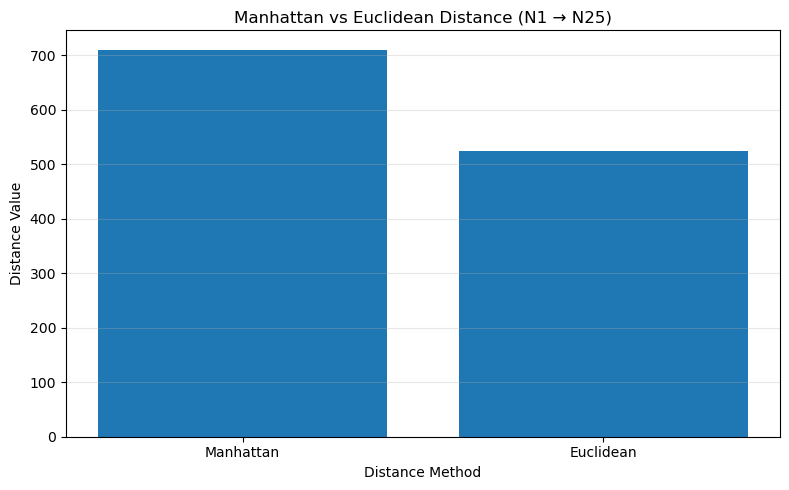

In [122]:
# GRAPH - MANHATTAN VS EUCLIDEAN
plt.figure(figsize=(8, 5))

plt.bar(
    distance_comparison["Distance Method"],
    distance_comparison["Distance Value"]
)

plt.xlabel("Distance Method")
plt.ylabel("Distance Value")

plt.title(
    f"Manhattan vs Euclidean Distance "
    f"({comparison_start} → {comparison_goal})"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [123]:
#  A* SEARCH

def astar(graph, start, goal, heuristic):

    open_set = []

    heapq.heappush(
        open_set,
        (heuristic(start, goal), 0, start)
    )

    came_from = {}

    g_score = {
        node: float("inf")
        for node in graph
    }

    g_score[start] = 0

    closed_set = set()

    nodes_expanded = 0

    while open_set:

        f_current, current_g, current = heapq.heappop(open_set)

        if current in closed_set:
            continue

        closed_set.add(current)
        nodes_expanded += 1

        if current == goal:

            path = []

            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)

            path.reverse()

            return {
                "path": path,
                "cost": g_score[goal],
                "nodes_expanded": nodes_expanded
                
            }

        for neighbour, edge_cost in graph[current]:

            tentative_g = g_score[current] + edge_cost

            if tentative_g < g_score[neighbour]:

                came_from[neighbour] = current

                g_score[neighbour] = tentative_g

                f_score = (
                    tentative_g
                    + heuristic(neighbour, goal)
                )

                heapq.heappush(
                    open_set,
                    (f_score, tentative_g, neighbour)
                )

    return {
        "path": None,
        "cost": float("inf"),
        "nodes_expanded": nodes_expanded
      
    }

In [124]:
# BASIC A* TEST

start_node = "N1"
goal_node = "N34"

start_time = time.perf_counter()

result = astar(
    graph_no_obstacles,
    start_node,
    goal_node,
    euclidean_heuristic
)

end_time = time.perf_counter()

execution_time = end_time - start_time

print("Start:", start_node)
print("Goal:", goal_node)
print("Path:", result["path"])
print("Path cost:", result["cost"])
print("Nodes expanded:", result["nodes_expanded"])
print("Execution time:", execution_time)

Start: N1
Goal: N34
Path: ['N1', 'N2', 'N3', 'N32', 'N10', 'N34']
Path cost: 1102.925006002916
Nodes expanded: 22
Execution time: 0.00038549999953829683


In [125]:

#  DISPLAY A* PATH


if result["path"] is not None:

    print("\nRecommended Route:")

    for i, node in enumerate(result["path"]):

        print(
            f"{i + 1}. {node} - "
            f"{node_names[node]}"
        )

else:

    print("No route found.")


Recommended Route:
1. N1 - Main Entrance
2. N2 - Jindal Global Law School
3. N3 - Jindal Global Business School
4. N32 - Global Library
5. N10 - Masters' Village
6. N34 - Jindal School of Environment and Sustainability


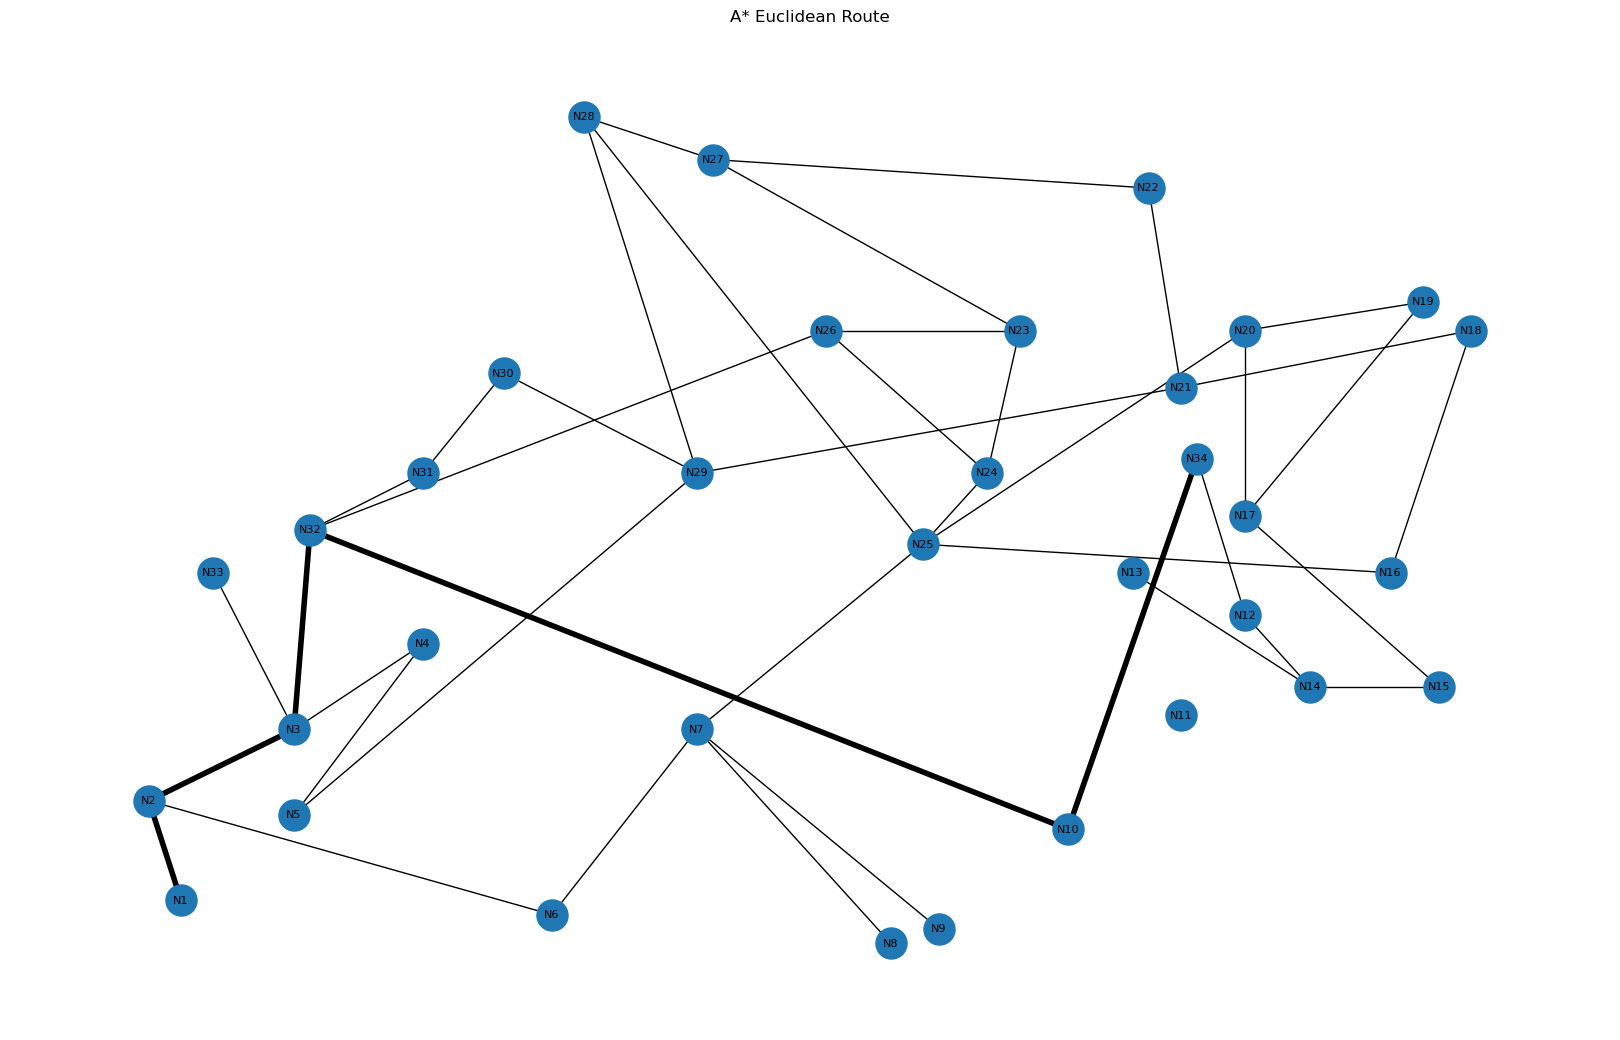

A* Route:
N1 → N2 → N3 → N32 → N10 → N34

Path Cost: 1102.925006002916
Nodes Expanded: 22


In [126]:

# VISUALISE SELECTED A* ROUTE

G = nx.Graph()

for node, (x, y) in coordinates.items():
    G.add_node(node, pos=(x, y))

for _, row in edges_df.iterrows():

    G.add_edge(
        row["From"],
        row["To"],
        weight=row["Distance"]
    )

pos = coordinates
plt.figure(figsize=(16, 10))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=500,
    font_size=8
)

if result["path"] is not None:

    route_edges = list(
        zip(
            result["path"][:-1],
            result["path"][1:]
        )
    )

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=route_edges,
        width=4
    )

plt.title("A* Euclidean Route")
plt.show()



if result["path"] is not None:

    print("A* Route:")
    print(" → ".join(result["path"]))

    print("\nPath Cost:", result["cost"])

    print("Nodes Expanded:", result["nodes_expanded"])

else:

    print("No route was found.")

In [127]:
# ACCESSIBILITY-AWARE HEURISTIC


def accessibility_heuristic(
    current,
    goal,
    edge_data
):

    # Base Euclidean estimate
    base_distance = euclidean_heuristic(
        current,
        goal
    )

    # Find environmental information
    connected_edges = edge_data[
        (edge_data["From"] == current) |
        (edge_data["To"] == current)
    ]

    if len(connected_edges) == 0:
        return base_distance

    # Average environmental difficulty
    average_slope = connected_edges["Slope"].mean()

    average_ramp_penalty = (
        1 - connected_edges["Ramp"].mean()
    )

    accessibility_penalty = (
        average_slope * 2
        + average_ramp_penalty * 5
    )

    return (
        base_distance
        + accessibility_penalty
    )

In [128]:
def aah(current, goal):
    return accessibility_heuristic(
        current,
        goal,
        edges_no_obstacles
    )

In [129]:
#  A* WITH ACCESSIBILITY-AWARE HEURISTIC


start_time = time.perf_counter()

aah_result = astar(
    graph_no_obstacles,
    start_node,
    goal_node,
    aah
)

end_time = time.perf_counter()

aah_time = end_time - start_time

print("Start:", start_node)
print("Goal:", goal_node)
print("Path:", aah_result["path"])
print("Path cost:", aah_result["cost"])
print("Nodes expanded:", aah_result["nodes_expanded"])
print("Execution time:", aah_time)

Start: N1
Goal: N34
Path: ['N1', 'N2', 'N3', 'N32', 'N10', 'N34']
Path cost: 1102.925006002916
Nodes expanded: 22
Execution time: 0.04203169999891543


In [130]:
#  COMPARE MANHATTAN, EUCLIDEAN AND AAH

test_cases = [
    ("N1", "N34"),
    ("N2", "N20"),
    ("N5", "N18"),
    ("N10", "N28"),
    ("N15", "N3")
]
heuristic_results = []

for start, goal in test_cases:

    # Euclidean A*
    start_time = time.perf_counter()

    euclidean_result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    euclidean_time = time.perf_counter() - start_time


    # Manhattan A*
    start_time = time.perf_counter()

    manhattan_result = astar(
        graph_no_obstacles,
        start,
        goal,
        manhattan_distance
    )

    manhattan_time = time.perf_counter() - start_time


    # Accessibility-Aware A*
    start_time = time.perf_counter()

    aah_result = astar(
        graph_no_obstacles,
        start,
        goal,
        lambda n, g: accessibility_heuristic(
            n,
            g,
            edges_no_obstacles
        )
    )

    aah_time = time.perf_counter() - start_time


    heuristic_results.append({
        "Start": start,
        "Goal": goal,

        "Euclidean Cost": euclidean_result["cost"],
        "Euclidean Time": euclidean_time,
        "Euclidean Expanded": euclidean_result["nodes_expanded"],

        "Manhattan Cost": manhattan_result["cost"],
        "Manhattan Time": manhattan_time,
        "Manhattan Expanded": manhattan_result["nodes_expanded"],

        "AAH Cost": aah_result["cost"],
        "AAH Time": aah_time,
        "AAH Expanded": aah_result["nodes_expanded"]
    })


heuristic_comparison_df = pd.DataFrame(
    heuristic_results
)

display(heuristic_comparison_df)

,Start,Goal,Euclidean Cost,Euclidean Time,Euclidean Expanded,Manhattan Cost,Manhattan Time,Manhattan Expanded,AAH Cost,AAH Time,AAH Expanded
0,N1,N34,1102.925006,0.000159,22,1102.925006,0.000112,20,1102.925006,0.033214,22
1,N2,N20,861.651710,0.000109,12,861.651710,0.000087,16,861.651710,0.035001,12
2,N5,N18,836.886529,0.000117,5,836.886529,0.000058,4,836.886529,0.016177,5
3,N10,N28,1079.966877,0.000094,11,1079.966877,0.000044,7,1079.966877,0.026859,11
4,N15,N3,1185.216391,0.000154,15,1185.216391,0.000071,13,1185.216391,0.033799,15


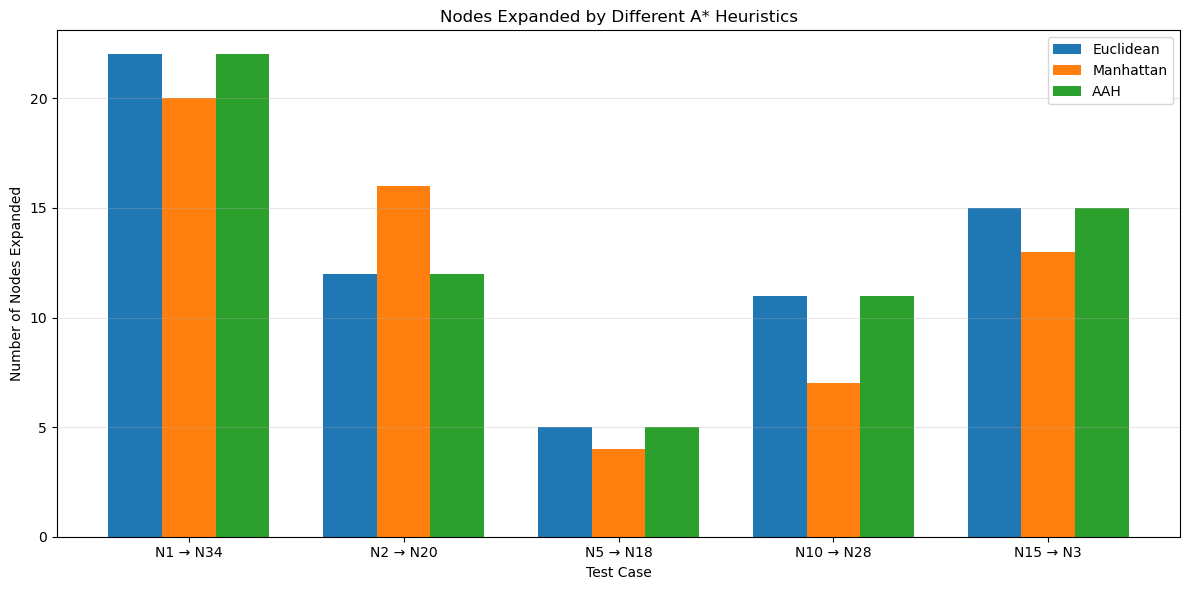

In [132]:
#  NODES EXPANDED COMPARISON

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    heuristic_comparison_df["Euclidean Expanded"],
    width,
    label="Euclidean"
)

plt.bar(
    x,
    heuristic_comparison_df["Manhattan Expanded"],
    width,
    label="Manhattan"
)

plt.bar(
    x + width,
    heuristic_comparison_df["AAH Expanded"],
    width,
    label="AAH"
)

plt.xticks(x, labels)
plt.xlabel("Test Case")
plt.ylabel("Number of Nodes Expanded")
plt.title("Nodes Expanded by Different A* Heuristics")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Blocked path segments:
['P12', 'P20', 'P30', 'P35']


,From,To,Path,Obstacle
11,N28,N25,P12,1
19,N23,N24,P20,1
29,N5,N29,P30,1
34,N10,N34,P35,1


No-obstacle graph created.
Obstacle-aware graph created.


C:\Users\HP\AppData\Local\Temp\ipykernel_8200\2586466040.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


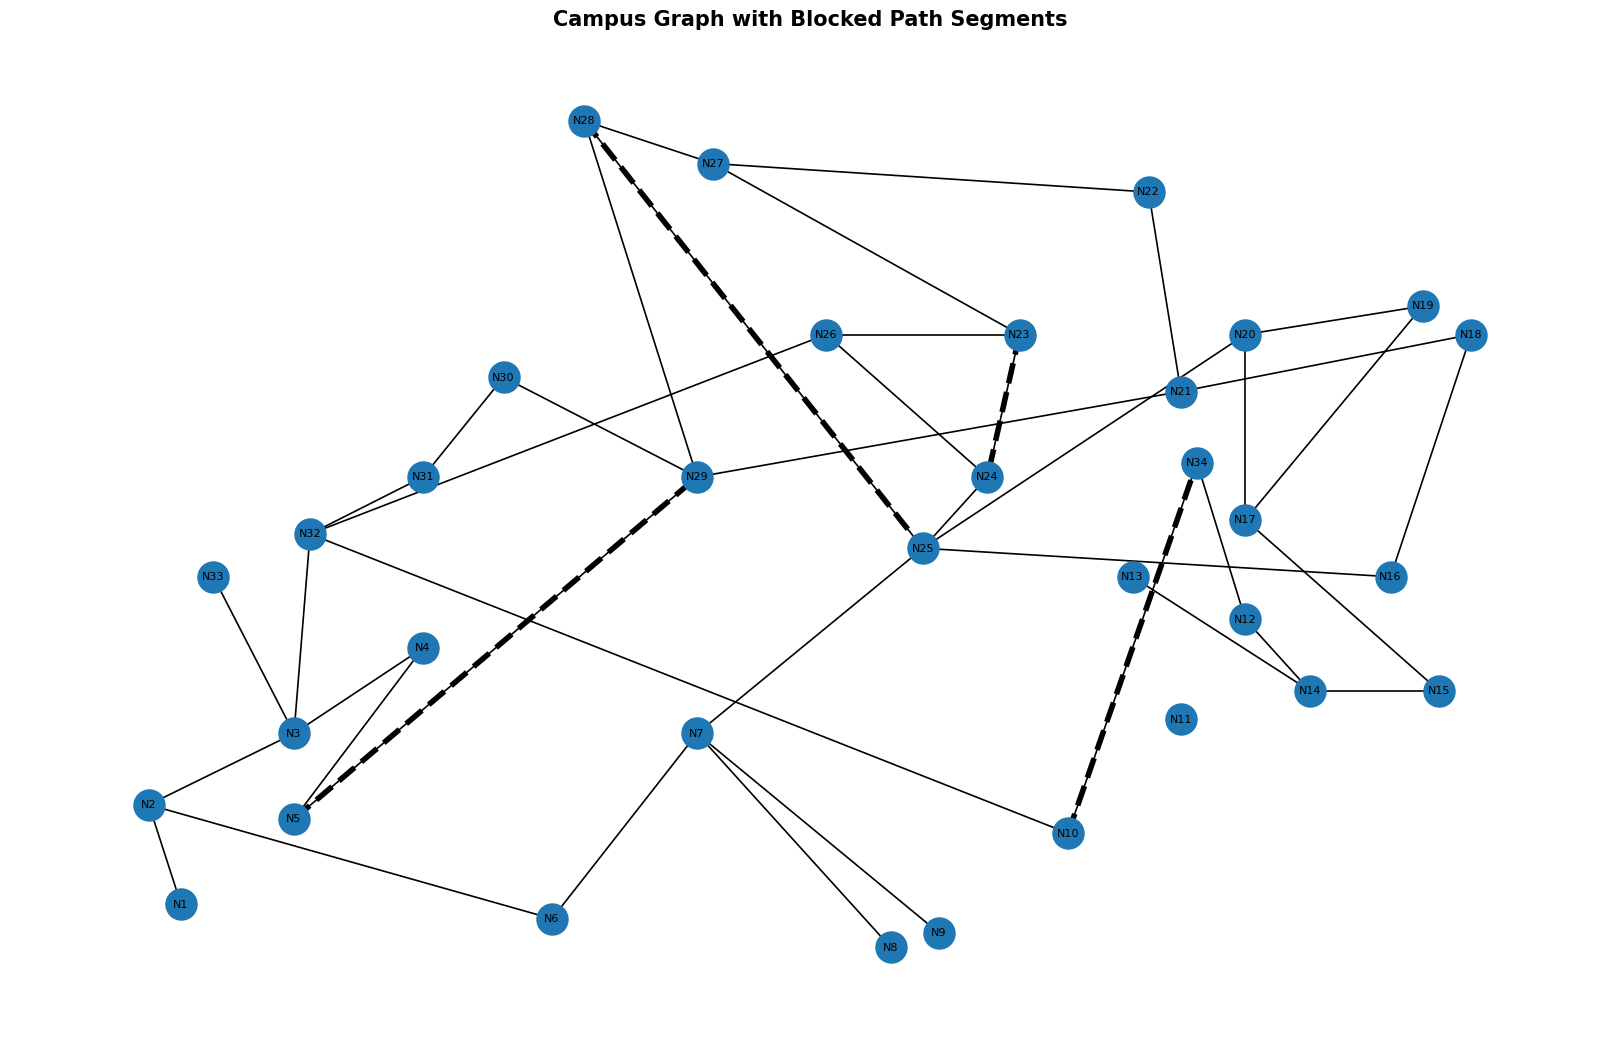

In [163]:
# TASK 3: ENVIRONMENTAL CONSTRAINTS


obstacle_paths = ["P12", "P20", "P30", "P35"]

edges_with_obstacles = edges_df.copy()

edges_with_obstacles["Obstacle"] = (
    edges_with_obstacles["Path"]
    .isin(obstacle_paths)
    .astype(int)
)

print("Blocked path segments:")
print(obstacle_paths)

display(
    edges_with_obstacles[
        edges_with_obstacles["Obstacle"] == 1
    ][["From", "To", "Path", "Obstacle"]]
)


# CREATE OBSTACLE AND NO-OBSTACLE GRAPHS


edges_no_obstacles = edges_df.copy()
edges_no_obstacles["Obstacle"] = 0

graph_no_obstacles = create_graph(
    edges_no_obstacles,
    include_obstacles=True
)

graph_with_obstacles = create_graph(
    edges_with_obstacles,
    include_obstacles=False
)

print("No-obstacle graph created.")
print("Obstacle-aware graph created.")

plt.figure(figsize=(16, 10))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=500,
    font_size=8,
    width=1.2
)

blocked_edges = []

for _, row in edges_with_obstacles.iterrows():

    if row["Obstacle"] == 1:
        blocked_edges.append(
            (row["From"], row["To"])
        )

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=blocked_edges,
    width=4,
    style="dashed"
)

plt.title(
    "Campus Graph with Blocked Path Segments",
    fontsize=15,
    fontweight="bold"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [133]:

#  DIJKSTRA'S ALGORITHM

def dijkstra(graph, start, goal):

    priority_queue = []

    heapq.heappush(
        priority_queue,
        (0, start)
    )

    distances = {
        node: float("inf")
        for node in graph
    }

    distances[start] = 0

    came_from = {}

    visited = set()

    nodes_expanded = 0

    while priority_queue:

        current_distance, current = heapq.heappop(
            priority_queue
        )

        if current in visited:
            continue

        visited.add(current)
        nodes_expanded += 1

        if current == goal:

            path = []

            while current in came_from:
                path.append(current)
                current = came_from[current]

            path.append(start)

            path.reverse()

            return {
                "path": path,
                "cost": distances[goal],
                "nodes_expanded": nodes_expanded
            }

        for neighbour, edge_cost in graph[current]:

            new_distance = (
                current_distance + edge_cost
            )

            if new_distance < distances[neighbour]:

                distances[neighbour] = new_distance

                came_from[neighbour] = current

                heapq.heappush(
                    priority_queue,
                    (new_distance, neighbour)
                )

    return {
        "path": None,
        "cost": float("inf"),
        "nodes_expanded": nodes_expanded
    }

In [134]:

# DIJKSTRA TEST


start_time = time.perf_counter()

dijkstra_result = dijkstra(
    graph_no_obstacles,
    start_node,
    goal_node
)

end_time = time.perf_counter()

dijkstra_time = end_time - start_time

print("Start:", start_node)
print("Goal:", goal_node)
print("Path:", dijkstra_result["path"])
print("Path cost:", dijkstra_result["cost"])
print("Nodes expanded:", dijkstra_result["nodes_expanded"])
print("Execution time:", dijkstra_time)

Start: N1
Goal: N34
Path: ['N1', 'N2', 'N3', 'N32', 'N10', 'N34']
Path cost: 1102.925006002916
Nodes expanded: 28
Execution time: 0.0002609999992273515


In [135]:
#  A* WITH OBSTACLES
obstacle_result = astar(
    graph_with_obstacles,
    start_node,
    goal_node,
    euclidean_heuristic
)

print("A* with obstacles")
print("Path:", obstacle_result["path"])
print("Cost:", obstacle_result["cost"])
print("Nodes expanded:", obstacle_result["nodes_expanded"])

A* with obstacles
Path: ['N1', 'N2', 'N6', 'N7', 'N25', 'N20', 'N17', 'N15', 'N14', 'N12', 'N34']
Cost: 1492.2072209837995
Nodes expanded: 32


In [136]:
# CELL 25: MULTIPLE START-GOAL TESTS


# Test cases
test_cases = [
    ("N1", "N34"),
    ("N2", "N20"),
    ("N5", "N18"),
    ("N10", "N28"),
    ("N15", "N3")
]

# Create an empty list to store results
results = []

# Run A* for every start-goal pair
for start, goal in test_cases:

    start_time = time.perf_counter()

    result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    end_time = time.perf_counter()

    results.append({
        "Start": start,
        "Goal": goal,
        "Algorithm": "A*",
        "Heuristic": "Euclidean",
        "Obstacles": "No",
        "Path Cost": result["cost"],
        "Nodes Expanded": result["nodes_expanded"],
        "Execution Time": end_time - start_time
    })

results_df = pd.DataFrame(results)

display(results_df)

,Start,Goal,Algorithm,Heuristic,Obstacles,Path Cost,Nodes Expanded,Execution Time
0,N1,N34,A*,Euclidean,No,1102.925006,22,0.000167
1,N2,N20,A*,Euclidean,No,861.651710,12,0.000074
2,N5,N18,A*,Euclidean,No,836.886529,5,0.000031
3,N10,N28,A*,Euclidean,No,1079.966877,11,0.000030
4,N15,N3,A*,Euclidean,No,1185.216391,15,0.000041


In [159]:

# COMPARE EUCLIDEAN AND AAH


comparison = []

for start, goal in test_cases:

    # Euclidean
    start_time = time.perf_counter()

    euclidean_result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    euclidean_time = (
        time.perf_counter() - start_time
    )

    # AAH
    def current_aah(node, target):
        return accessibility_heuristic(
            node,
            target,
            edges_no_obstacles
        )

    start_time = time.perf_counter()

    aah_result = astar(
        graph_no_obstacles,
        start,
        goal,
        current_aah
    )

    aah_time = (
        time.perf_counter() - start_time
    )

    comparison.append({
        "Start": start,
        "Goal": goal,
        "Euclidean Cost": euclidean_result["cost"],
        "AAH Cost": aah_result["cost"],
        "Euclidean Nodes": euclidean_result["nodes_expanded"],
        "AAH Nodes": aah_result["nodes_expanded"],
        "Euclidean Time": euclidean_time,
        "AAH Time": aah_time
    })

heuristic_comparison_df = pd.DataFrame(
    comparison
)

display(heuristic_comparison_df)


print("Columns in comparison table:")
print(heuristic_comparison_df.columns.tolist())

,Start,Goal,Euclidean Cost,AAH Cost,Euclidean Nodes,AAH Nodes,Euclidean Time,AAH Time
0,N1,N34,1102.925006,1102.925006,22,22,0.000160,0.039015
1,N2,N20,861.651710,861.651710,12,12,0.000140,0.029688
2,N5,N18,836.886529,836.886529,5,5,0.000038,0.005145
3,N10,N28,1079.966877,1079.966877,11,11,0.000044,0.010371
4,N15,N3,1185.216391,1185.216391,15,15,0.000035,0.006609


Columns in comparison table:
['Start', 'Goal', 'Euclidean Cost', 'AAH Cost', 'Euclidean Nodes', 'AAH Nodes', 'Euclidean Time', 'AAH Time']


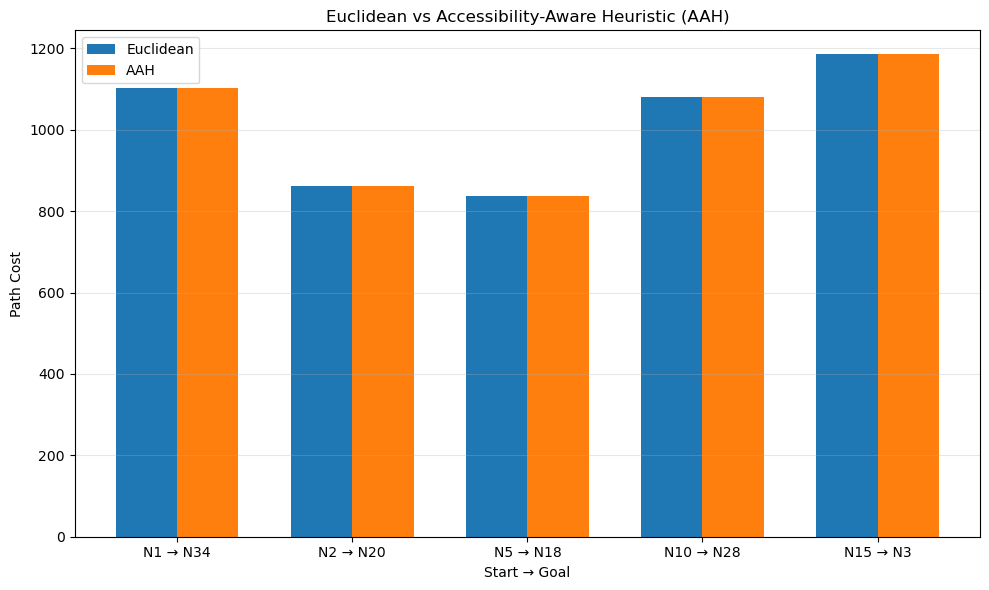

In [160]:

# GRAPH: EUCLIDEAN VS AAH COST


plt.figure(figsize=(10, 6))

x = np.arange(len(heuristic_comparison_df))

width = 0.35

plt.bar(
    x - width / 2,
    heuristic_comparison_df["Euclidean Cost"],
    width,
    label="Euclidean"
)

plt.bar(
    x + width / 2,
    heuristic_comparison_df["AAH Cost"],
    width,
    label="AAH"
)

plt.xlabel("Start → Goal")
plt.ylabel("Path Cost")
plt.title("Euclidean vs Accessibility-Aware Heuristic (AAH)")

plt.xticks(
    x,
    heuristic_comparison_df["Start"] + " → " +
    heuristic_comparison_df["Goal"]
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [138]:

# CELL 27: A* VS DIJKSTRA

algorithm_results = []

for start, goal in test_cases:

    # A*
    start_time = time.perf_counter()

    a_result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    a_time = time.perf_counter() - start_time

    # Dijkstra
    start_time = time.perf_counter()

    d_result = dijkstra(
        graph_no_obstacles,
        start,
        goal
    )

    d_time = time.perf_counter() - start_time

    algorithm_results.append({
        "Start": start,
        "Goal": goal,
        "A* Cost": a_result["cost"],
        "Dijkstra Cost": d_result["cost"],
        "A* Nodes": a_result["nodes_expanded"],
        "Dijkstra Nodes": d_result["nodes_expanded"],
        "A* Time": a_time,
        "Dijkstra Time": d_time
    })

algorithm_comparison_df = pd.DataFrame(
    algorithm_results
)

algorithm_comparison_df

,Start,Goal,A* Cost,Dijkstra Cost,A* Nodes,Dijkstra Nodes,A* Time,Dijkstra Time
0,N1,N34,1102.925006,1102.925006,22,28,0.000162,0.000087
1,N2,N20,861.651710,861.651710,12,22,0.000079,0.000064
2,N5,N18,836.886529,836.886529,5,18,0.000037,0.000052
3,N10,N28,1079.966877,1079.966877,11,25,0.000057,0.000061
4,N15,N3,1185.216391,1185.216391,15,26,0.000072,0.000059


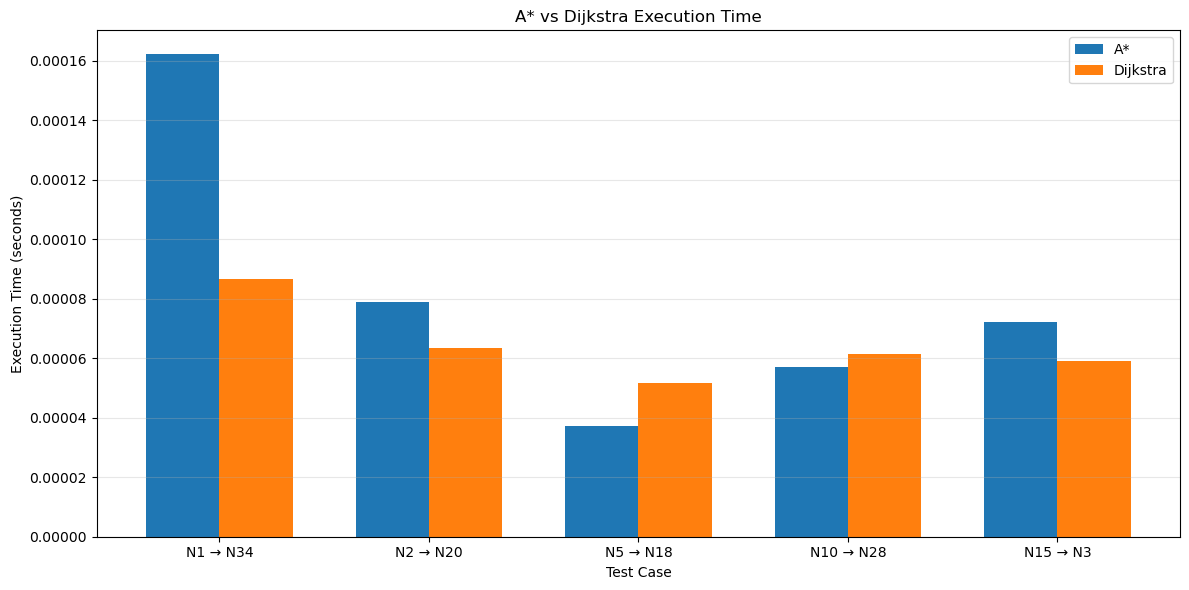

In [140]:
#  GRAPH  - A* VS DIJKSTRA EXECUTION TIME


# Create x-axis positions
x = np.arange(len(algorithm_comparison_df))

# Width of each bar
width = 0.35

plt.figure(figsize=(12, 6))

# A* execution time
plt.bar(
    x - width / 2,
    algorithm_comparison_df["A* Time"],
    width,
    label="A*"
)

# Dijkstra execution time
plt.bar(
    x + width / 2,
    algorithm_comparison_df["Dijkstra Time"],
    width,
    label="Dijkstra"
)

# X-axis labels
labels = (
    algorithm_comparison_df["Start"].astype(str)
    + " → "
    + algorithm_comparison_df["Goal"].astype(str)
)

plt.xticks(x, labels)

plt.ylabel("Execution Time (seconds)")
plt.xlabel("Test Case")
plt.title("A* vs Dijkstra Execution Time")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

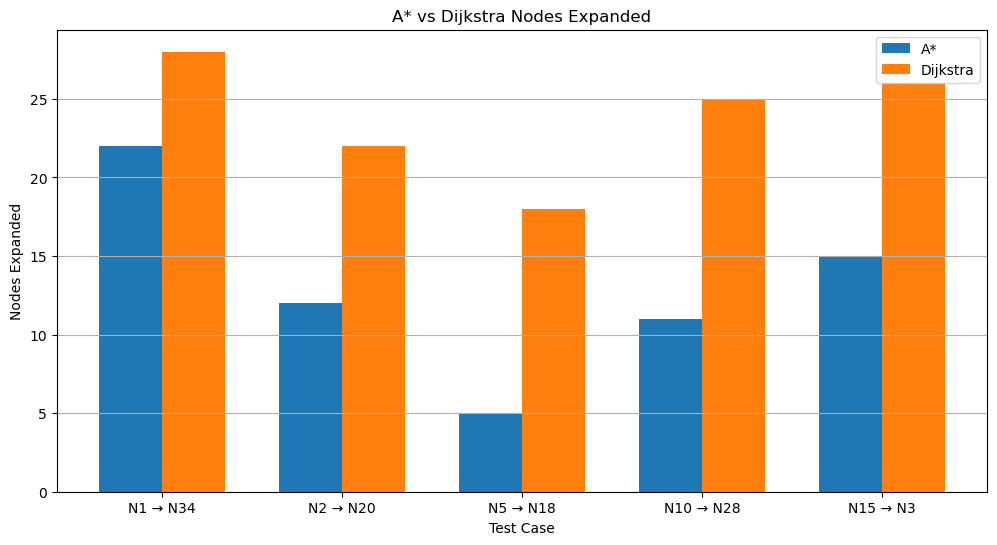

In [141]:

# A* VS DIJKSTRA NODES EXPANDED


plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    algorithm_comparison_df["A* Nodes"],
    width,
    label="A*"
)

plt.bar(
    x + width / 2,
    algorithm_comparison_df["Dijkstra Nodes"],
    width,
    label="Dijkstra"
)

plt.xticks(
    x,
    algorithm_comparison_df["Start"]
    + " → "
    + algorithm_comparison_df["Goal"]
)

plt.ylabel("Nodes Expanded")
plt.xlabel("Test Case")
plt.title("A* vs Dijkstra Nodes Expanded")
plt.legend()
plt.grid(axis="y")

plt.show()

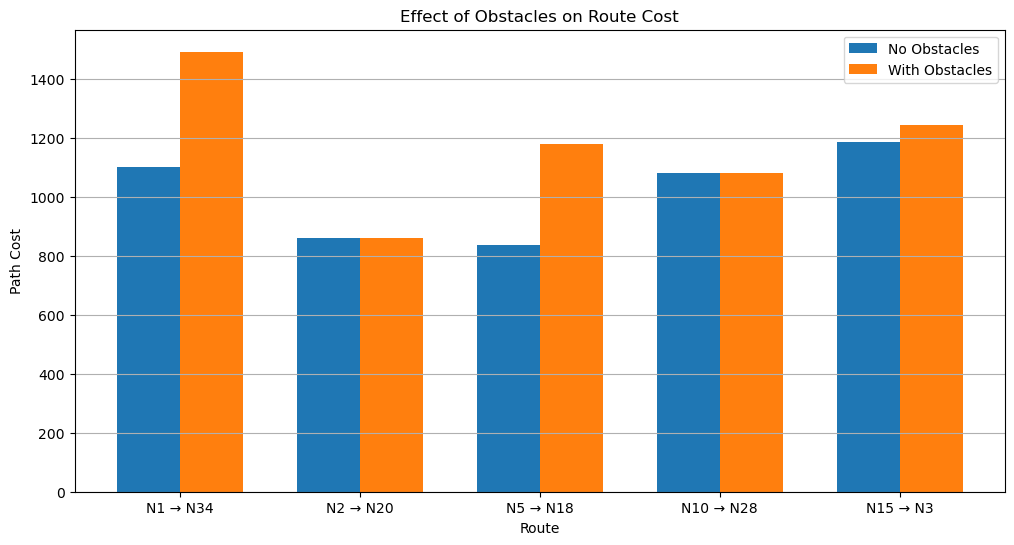

In [142]:

 ## EFFECT OF OBSTACLES


obstacle_comparison = []

for start, goal in test_cases:

    no_obstacle_result = astar(
        graph_no_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    obstacle_result = astar(
        graph_with_obstacles,
        start,
        goal,
        euclidean_heuristic
    )

    obstacle_comparison.append({
        "Route": f"{start} → {goal}",
        "No Obstacles": no_obstacle_result["cost"],
        "With Obstacles": obstacle_result["cost"]
    })

obstacle_df = pd.DataFrame(obstacle_comparison)

plt.figure(figsize=(12, 6))

x2 = np.arange(len(obstacle_df))

plt.bar(
    x2 - width / 2,
    obstacle_df["No Obstacles"],
    width,
    label="No Obstacles"
)

plt.bar(
    x2 + width / 2,
    obstacle_df["With Obstacles"],
    width,
    label="With Obstacles"
)

plt.xticks(
    x2,
    obstacle_df["Route"]
)

plt.ylabel("Path Cost")
plt.xlabel("Route")
plt.title("Effect of Obstacles on Route Cost")
plt.legend()
plt.grid(axis="y")

plt.show()

In [143]:

# EXTENDED MAP FOR SCALABILITY TESTING


def create_extended_graph(base_edges, scale_factor):

    extended_graph = {}

    
    # Create copies of the original graph

    for copy_number in range(scale_factor):

        prefix = f"S{copy_number + 1}_"

        for _, row in base_edges.iterrows():

            start = prefix + row["From"]
            end = prefix + row["To"]
            cost = row["Distance"]

            if start not in extended_graph:
                extended_graph[start] = []

            if end not in extended_graph:
                extended_graph[end] = []

            extended_graph[start].append(
                (end, cost)
            )

            extended_graph[end].append(
                (start, cost)
            )
    # Connect consecutive graph copies

    for copy_number in range(scale_factor - 1):

        current_prefix = f"S{copy_number + 1}_"
        next_prefix = f"S{copy_number + 2}_"

        # Connect corresponding N1 nodes
        current_node = current_prefix + "N1"
        next_node = next_prefix + "N1"

        connection_cost = 1.0

        extended_graph[current_node].append(
            (next_node, connection_cost)
        )

        extended_graph[next_node].append(
            (current_node, connection_cost)
        )

    return extended_graph

In [144]:

# CREATE DIFFERENT GRAPH SIZES


scalability_graphs = {}

scale_factors = [
    1,
    2,
    4,
    8
]

for factor in scale_factors:

    scalability_graphs[factor] = create_extended_graph(
        edges_df,
        factor
    )


# Display graph sizes

scalability_summary = []

for factor, graph in scalability_graphs.items():

    number_of_nodes = len(graph)

    number_of_edges = sum(
        len(neighbours)
        for neighbours in graph.values()
    ) // 2

    scalability_summary.append({
        "Scale Factor": factor,
        "Nodes": number_of_nodes,
        "Edges": number_of_edges
    })


scalability_df = pd.DataFrame(
    scalability_summary
)

display(scalability_df)

,Scale Factor,Nodes,Edges
0,1,33,42
1,2,66,85
2,4,132,171
3,8,264,343


In [145]:
# CELL 33C: A* VS DIJKSTRA SCALABILITY TEST


scalability_results = []


for factor, graph in scalability_graphs.items():

    start_node = "S1_N1"

    goal_node = f"S{factor}_N34"


# A* scalability test

    start_time = time.perf_counter()

    astar_result = astar(
        graph,
        start_node,
        goal_node,
        lambda a, b: 0
    )

    astar_time = (
        time.perf_counter()
        - start_time
    )


    
    # Dijkstra scalability test
    

    start_time = time.perf_counter()

    dijkstra_result = dijkstra(
        graph,
        start_node,
        goal_node
    )

    dijkstra_time = (
        time.perf_counter()
        - start_time
    )


# store A* result
    scalability_results.append({
        "Scale Factor": factor,
        "Nodes": len(graph),
        "Algorithm": "A*",
        "Path Cost": astar_result["cost"],
        "Nodes Expanded": astar_result["nodes_expanded"],
        "Execution Time": astar_time
    })


    
    # Store Dijkstra result

    scalability_results.append({
        "Scale Factor": factor,
        "Nodes": len(graph),
        "Algorithm": "Dijkstra",
        "Path Cost": dijkstra_result["cost"],
        "Nodes Expanded": dijkstra_result["nodes_expanded"],
        "Execution Time": dijkstra_time
    })


scalability_results_df = pd.DataFrame(
    scalability_results
)

display(
    scalability_results_df
)

,Scale Factor,Nodes,Algorithm,Path Cost,Nodes Expanded,Execution Time
0,1,33,A*,1102.925006,28,0.000133
1,1,33,Dijkstra,1102.925006,28,0.000083
2,2,66,A*,1103.925006,56,0.000208
3,2,66,Dijkstra,1103.925006,56,0.000144
4,4,132,A*,1105.925006,112,0.000387
5,4,132,Dijkstra,1105.925006,112,0.000304
6,8,264,A*,1109.925006,224,0.000747
7,8,264,Dijkstra,1109.925006,224,0.000555


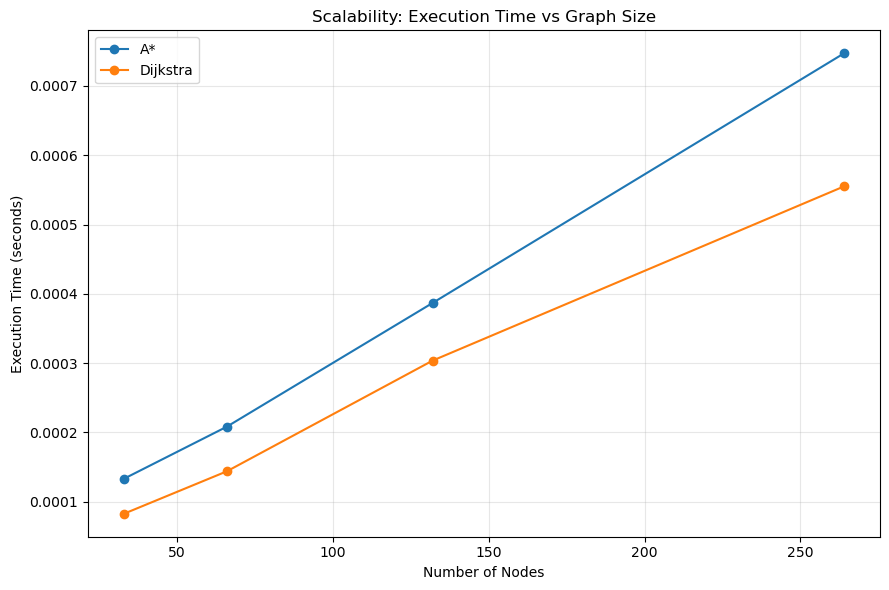

In [146]:
# SCALABILITY - EXECUTION TIME

plt.figure(figsize=(9, 6))

for algorithm in ["A*", "Dijkstra"]:

    data = scalability_results_df[
        scalability_results_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Nodes"],
        data["Execution Time"],
        marker="o",
        label=algorithm
    )


plt.xlabel("Number of Nodes")
plt.ylabel("Execution Time (seconds)")

plt.title(
    "Scalability: Execution Time vs Graph Size"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [147]:
# COMPLEXITY TABLE


complexity_df = pd.DataFrame({
    "Algorithm": [
        "A*",
        "A*",
        "Dijkstra"
    ],
    "Heuristic": [
        "Euclidean",
        "Accessibility-Aware",
        "None"
    ],
    "Time Complexity": [
        "Depends on heuristic and graph structure; worst-case exponential search",
        "Depends on heuristic and graph structure; worst-case exponential search",
        "O((V + E) log V) with binary heap"
    ],
    "Space Complexity": [
        "O(V) typical graph-search storage",
        "O(V) typical graph-search storage",
        "O(V)"
    ],
    "Complete": [
        "Under stated search assumptions",
        "Under stated search assumptions",
        "Yes for finite graphs with non-negative costs"
    ],
    "Optimality": [
        "Requires appropriate admissible/consistent heuristic conditions",
        "Must be analysed because penalty may affect admissibility",
        "Yes for non-negative edge costs"
    ]
})

complexity_df

,Algorithm,Heuristic,Time Complexity,Space Complexity,Complete,Optimality
0,A*,Euclidean,Depends on heuristic and graph structure; wors...,O(V) typical graph-search storage,Under stated search assumptions,Requires appropriate admissible/consistent heu...
1,A*,Accessibility-Aware,Depends on heuristic and graph structure; wors...,O(V) typical graph-search storage,Under stated search assumptions,Must be analysed because penalty may affect ad...
2,Dijkstra,None,O((V + E) log V) with binary heap,O(V),Yes for finite graphs with non-negative costs,Yes for non-negative edge costs


In [148]:

# HEURISTIC ANALYSIS

heuristic_analysis = []

for start, goal in test_cases:

    result = dijkstra(
        graph_no_obstacles,
        start,
        goal
    )

    if result["path"] is not None:

        for node in result["path"]:

            h_e = euclidean_heuristic(
                node,
                goal
            )

            h_a = accessibility_heuristic(
                node,
                goal,
                edges_no_obstacles
            )

            heuristic_analysis.append({
                "Start": start,
                "Goal": goal,
                "Node": node,
                "Euclidean": h_e,
                "AAH": h_a
            })

heuristic_analysis_df = pd.DataFrame(
    heuristic_analysis
)

heuristic_analysis_df

,Start,Goal,Node,Euclidean,AAH
0,N1,N34,N1,702.139587,707.139587
1,N1,N34,N2,692.892488,695.892488
2,N1,N34,N3,591.354378,591.354378
3,N1,N34,N32,552.268051,552.768051
4,N1,N34,N10,272.029410,274.029410
5,N1,N34,N34,0.000000,5.500000
6,N2,N20,N2,755.843899,758.843899
7,N2,N20,N6,594.138031,597.138031
8,N2,N20,N7,440.454311,443.654311
9,N2,N20,N25,250.000000,252.600000


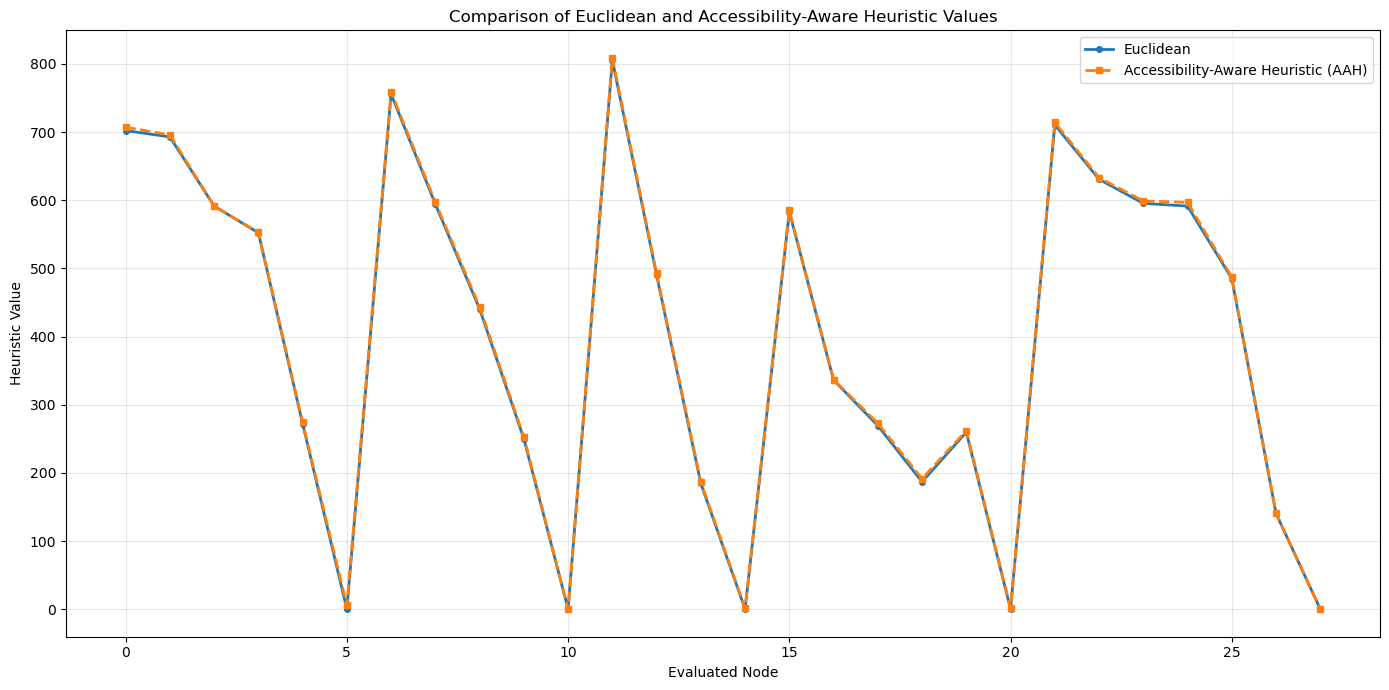

In [149]:
# HEURISTIC VALUES


plt.figure(figsize=(14, 7))

plt.plot(
    heuristic_analysis_df["Euclidean"].values,
    marker="o",
    markersize=4,
    linewidth=2,
    label="Euclidean"
)

plt.plot(
    heuristic_analysis_df["AAH"].values,
    marker="s",
    markersize=4,
    linewidth=2,
    linestyle="--",
    label="Accessibility-Aware Heuristic (AAH)"
)

plt.xlabel("Evaluated Node")
plt.ylabel("Heuristic Value")
plt.title("Comparison of Euclidean and Accessibility-Aware Heuristic Values")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [150]:
# Final summary
print("\nNumber of nodes:", len(node_names))
print("Number of paths:", len(edges_df))

print(
    "\nAverage path distance:",
    edges_df["Distance"].mean()
)

print(
    "Maximum path distance:",
    edges_df["Distance"].max()
)

print(
    "Minimum path distance:",
    edges_df["Distance"].min()
)

print("\nHeuristic comparison:")
display(heuristic_comparison_df)

print("\nAlgorithm comparison:")
display(algorithm_comparison_df)

print("\nObstacle comparison:")
display(obstacle_df)


Number of nodes: 34
Number of paths: 42

Average path distance: 181.23337978164528
Maximum path distance: 514.78150704935
Minimum path distance: 64.03124237432849

Heuristic comparison:


,Start,Goal,Euclidean Cost,AAH Cost,Euclidean Nodes,AAH Nodes,Euclidean Time,AAH Time
0,N1,N34,1102.925006,1102.925006,22,22,0.000235,0.038060
1,N2,N20,861.651710,861.651710,12,12,0.000108,0.035377
2,N5,N18,836.886529,836.886529,5,5,0.000073,0.015273
3,N10,N28,1079.966877,1079.966877,11,11,0.000135,0.026063
4,N15,N3,1185.216391,1185.216391,15,15,0.000167,0.026800



Algorithm comparison:


,Start,Goal,A* Cost,Dijkstra Cost,A* Nodes,Dijkstra Nodes,A* Time,Dijkstra Time
0,N1,N34,1102.925006,1102.925006,22,28,0.000162,0.000087
1,N2,N20,861.651710,861.651710,12,22,0.000079,0.000064
2,N5,N18,836.886529,836.886529,5,18,0.000037,0.000052
3,N10,N28,1079.966877,1079.966877,11,25,0.000057,0.000061
4,N15,N3,1185.216391,1185.216391,15,26,0.000072,0.000059



Obstacle comparison:


,Route,No Obstacles,With Obstacles
0,N1 → N34,1102.925006,1492.207221
1,N2 → N20,861.651710,861.651710
2,N5 → N18,836.886529,1180.481070
3,N10 → N28,1079.966877,1079.966877
4,N15 → N3,1185.216391,1244.799899


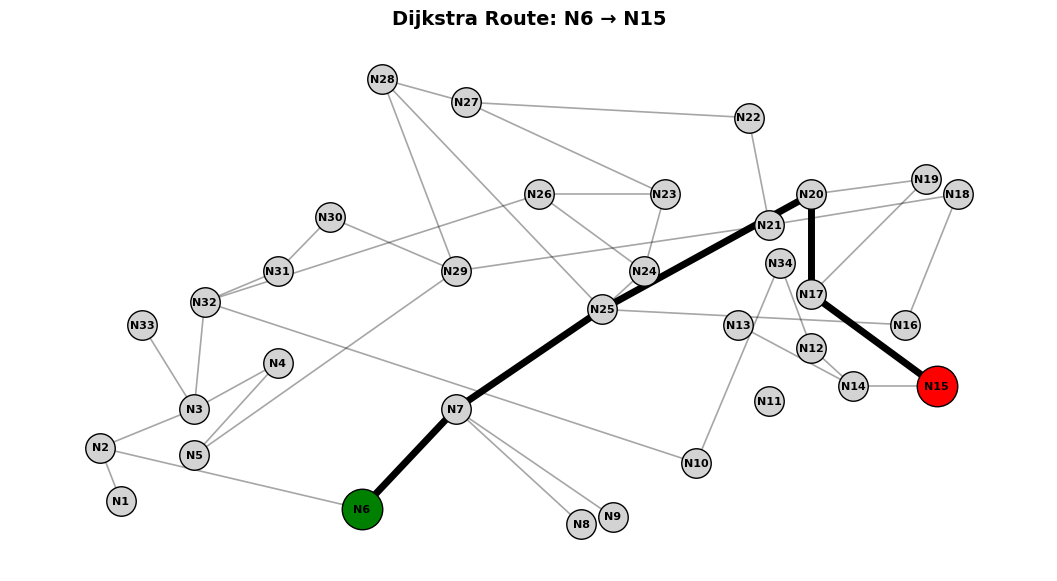

In [181]:

#  WHEELCHAIR CAMPUS NAVIGATION GUI

import tkinter as tk
from tkinter import ttk, messagebox
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg



#  CREATE MAIN WINDOW
root = tk.Tk()

root.title(
    "Wheelchair Accessible Campus Navigation - Jindal Global University"
)

root.geometry("1450x850")

root.configure(bg="white")



title = tk.Label(
    root,
    text="Wheelchair Accessible Campus Navigation",
    font=("Arial", 22, "bold"),
    bg="white"
)

title.pack(pady=(10, 2))


subtitle = tk.Label(
    root,
    text="Jindal Global University | A* Pathfinding System",
    font=("Arial", 12),
    bg="white"
)

subtitle.pack(pady=(0, 10))


# TOP CONTROL FRAME

control_frame = tk.Frame(
    root,
    bg="white",
    bd=1,
    relief="solid"
)

control_frame.pack(
    fill="x",
    padx=15,
    pady=5
)



# START LOCATION

tk.Label(
    control_frame,
    text="Start Location",
    font=("Arial", 11, "bold"),
    bg="white"
).grid(
    row=0,
    column=0,
    padx=(15, 5),
    pady=15
)


start_var = tk.StringVar()

start_dropdown = ttk.Combobox(
    control_frame,
    textvariable=start_var,
    values=list(node_names.keys()),
    state="readonly",
    width=15
)

start_dropdown.grid(
    row=0,
    column=1,
    padx=5
)



# DESTINATION
tk.Label(
    control_frame,
    text="Destination",
    font=("Arial", 11, "bold"),
    bg="white"
).grid(
    row=0,
    column=2,
    padx=(25, 5)
)


goal_var = tk.StringVar()

goal_dropdown = ttk.Combobox(
    control_frame,
    textvariable=goal_var,
    values=list(node_names.keys()),
    state="readonly",
    width=15
)

goal_dropdown.grid(
    row=0,
    column=3,
    padx=5
)


# ALGORITHM
tk.Label(
    control_frame,
    text="Algorithm",
    font=("Arial", 11, "bold"),
    bg="white"
).grid(
    row=0,
    column=4,
    padx=(25, 5)
)


algorithm_var = tk.StringVar()

algorithm_dropdown = ttk.Combobox(
    control_frame,
    textvariable=algorithm_var,
    values=[
        "A*",
        "Dijkstra"
    ],
    state="readonly",
    width=15
)

algorithm_dropdown.grid(
    row=0,
    column=5,
    padx=5
)

algorithm_dropdown.current(0)



# HEURISTIC

tk.Label(
    control_frame,
    text="Heuristic",
    font=("Arial", 11, "bold"),
    bg="white"
).grid(
    row=0,
    column=6,
    padx=(25, 5)
)


heuristic_var = tk.StringVar()

heuristic_dropdown = ttk.Combobox(
    control_frame,
    textvariable=heuristic_var,
    values=[
        "Euclidean",
        "Manhattan"
    ],
    state="readonly",
    width=15
)

heuristic_dropdown.grid(
    row=0,
    column=7,
    padx=5
)

heuristic_dropdown.current(0)



#  MAIN CONTENT FRAME
main_frame = tk.Frame(
    root,
    bg="white"
)

main_frame.pack(
    fill="both",
    expand=True,
    padx=15,
    pady=10
)



# MAP FRAME

map_frame = tk.Frame(
    main_frame,
    bg="white",
    bd=1,
    relief="solid"
)

map_frame.pack(
    side="left",
    fill="both",
    expand=True,
    padx=(0, 10)
)



#  INFORMATION FRAME

info_frame = tk.Frame(
    main_frame,
    bg="white",
    width=390,
    bd=1,
    relief="solid"
)

info_frame.pack(
    side="right",
    fill="y"
)

info_frame.pack_propagate(False)



# MAP FIGURE
fig, ax = plt.subplots(
    figsize=(9, 7)
)

fig.subplots_adjust(
    left=0.04,
    right=0.98,
    bottom=0.05,
    top=0.92
)


canvas = FigureCanvasTkAgg(
    fig,
    master=map_frame
)

canvas_widget = canvas.get_tk_widget()

canvas_widget.pack(
    fill="both",
    expand=True
)


#  INFORMATION TITLE

info_title = tk.Label(
    info_frame,
    text="ROUTE INFORMATION",
    font=("Arial", 16, "bold"),
    bg="white"
)

info_title.pack(
    pady=(15, 10)
)


# INFORMATION TEXT BOX
info_text = tk.Text(
    info_frame,
    width=42,
    height=30,
    font=("Arial", 10),
    wrap="word",
    bg="#f7f7f7"
)

info_text.pack(
    padx=15,
    pady=5,
    fill="both",
    expand=True
)

# 10. HELPER FUNCTION: FIND PATH INFORMATION

def get_route_information(route):

    route_edges = list(
        zip(
            route[:-1],
            route[1:]
        )
    )

    route_paths = []

    route_distances = []

    route_obstacles = []

    route_landmarks = []

    # Examine every edge in the selected route

    for u, v in route_edges:

        matching_edges = edges_df[
            (
                (edges_df["From"] == u) &
                (edges_df["To"] == v)
            )
            |
            (
                (edges_df["From"] == v) &
                (edges_df["To"] == u)
            )
        ]

        if len(matching_edges) > 0:

            row = matching_edges.iloc[0]

            route_paths.append(
                row["Path"]
            )

            route_distances.append(
                row["Distance"]
            )

            # Check obstacle
            if row["Path"] in obstacle_paths:

                route_obstacles.append(
                    row["Path"]
                )

            # Landmark

            if row["From"] in node_names:

                route_landmarks.append(
                    row["From"]
                )

            if row["To"] in node_names:

                route_landmarks.append(
                    row["To"]
                )


    # Remove duplicate landmarks
    route_landmarks = list(
        dict.fromkeys(route_landmarks)
    )


    return (
        route_edges,
        route_paths,
        route_distances,
        route_obstacles,
        route_landmarks
    )

# DRAW INITIAL CAMPUS MAP
def draw_initial_map():

    ax.clear()

    # Draw campus graph
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        width=1.5,
        alpha=0.45
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_size=500,
        node_color="lightgray",
        edgecolors="black"
    )

    nx.draw_networkx_labels(
        G,
        pos,
        ax=ax,
        font_size=8,
        font_weight="bold"
    )

    ax.set_title(
        "Jindal Global University Campus Network",
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

    canvas.draw()


draw_initial_map()

#  CALCULATE ROUTE

def calculate_route():

    start = start_var.get()

    goal = goal_var.get()

    algorithm = algorithm_var.get()

    heuristic_name = heuristic_var.get()


   
    # Validate input
    if start == "" or goal == "":

        messagebox.showwarning(
            "Missing Input",
            "Please select both a start location and destination."
        )

        return


    if start == goal:

        messagebox.showwarning(
            "Invalid Route",
            "Start and destination must be different."
        )

        return

    # Select heuristic
\
    if heuristic_name == "Euclidean":

        selected_heuristic = euclidean_heuristic

    else:

        selected_heuristic = manhattan_distance


    
    # Run selected algorithm

    if algorithm == "A*":

        result = astar(
            graph_no_obstacles,
            start,
            goal,
            selected_heuristic
        )

    else:

        result = dijkstra(
            graph_no_obstacles,
            start,
            goal
        )

    # Clear old map

    ax.clear()


# draw complete graph

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        width=1.2,
        alpha=0.35
    )


    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_size=450,
        node_color="lightgray",
        edgecolors="black"
    )


    nx.draw_networkx_labels(
        G,
        pos,
        ax=ax,
        font_size=8,
        font_weight="bold"
    )

    # No route

    if result["path"] is None:

        ax.set_title(
            "No Route Found",
            fontsize=14,
            fontweight="bold"
        )

        ax.axis("off")

        canvas.draw()

        info_text.delete(
            "1.0",
            tk.END
        )

        info_text.insert(
            tk.END,
            "NO ROUTE FOUND\n\n"
            "The selected locations are not connected "
            "in the current campus graph."
        )

        return

    # Get route
    route = result["path"]

    route_edges = list(
        zip(
            route[:-1],
            route[1:]
        )
    )


    # Draw route
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        edgelist=route_edges,
        width=5
    )

    # Highlight start

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        nodelist=[start],
        node_size=850,
        node_color="green",
        edgecolors="black"
    )

    # Highlight destination
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        nodelist=[goal],
        node_size=850,
        node_color="red",
        edgecolors="black"
    )


    (
        route_edges,
        route_paths,
        route_distances,
        route_obstacles,
        route_landmarks
    ) = get_route_information(route)




    path_cost = result["cost"]

    nodes_expanded = result["nodes_expanded"]

    total_distance = sum(
        route_distances
    )



    # Estimated traversal time
    # Assumption:
    # 1 distance unit = approximately 1 second .This is a model estimate, not real measured travel time.


    estimated_time_seconds = total_distance


    minutes = int(
        estimated_time_seconds // 60
    )

    seconds = int(
        estimated_time_seconds % 60
    )

    # Route cost summary
    number_of_segments = len(
        route_edges
    )


    # Map title

    ax.set_title(
        f"{algorithm} Route: {start} → {goal}",
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

    canvas.draw()



    # DISPLAY INFORMATION

    info_text.delete(
        "1.0",
        tk.END
    )


    info_text.insert(
        tk.END,
        "ROUTE SUMMARY\n"
    )

    info_text.insert(
        tk.END,
        "==============================\n\n"
    )


    info_text.insert(
        tk.END,
        f"Start Location:\n"
        f"{start}\n\n"
    )


    info_text.insert(
        tk.END,
        f"Destination:\n"
        f"{goal}\n\n"
    )


    info_text.insert(
        tk.END,
        f"Algorithm: {algorithm}\n"
    )


    if algorithm == "A*":

        info_text.insert(
            tk.END,
            f"Heuristic: {heuristic_name}\n"
        )


    info_text.insert(
        tk.END,
        "\n------------------------------\n"
    )


    info_text.insert(
        tk.END,
        "CALCULATED PATH\n"
    )

    info_text.insert(
        tk.END,
        "------------------------------\n\n"
    )


    info_text.insert(
        tk.END,
        " → ".join(route)
        + "\n\n"
    )


    info_text.insert(
        tk.END,
        "------------------------------\n"
    )


    info_text.insert(
        tk.END,
        "COST INFORMATION\n"
    )

    info_text.insert(
        tk.END,
        "------------------------------\n\n"
    )


    info_text.insert(
        tk.END,
        f"Path Cost: {path_cost:.2f}\n"
    )

    info_text.insert(
        tk.END,
        f"Total Distance: {total_distance:.2f}\n"
    )

    info_text.insert(
        tk.END,
        f"Path Segments: {number_of_segments}\n"
    )

    info_text.insert(
        tk.END,
        f"Nodes Expanded: {nodes_expanded}\n"
    )


    info_text.insert(
        tk.END,
        "\n------------------------------\n"
    )


    info_text.insert(
        tk.END,
        "TRAVERSAL INFORMATION\n"
    )

    info_text.insert(
        tk.END,
        "------------------------------\n\n"
    )


    info_text.insert(
        tk.END,
        f"Estimated Time: "
        f"{minutes} min {seconds} sec\n"
    )


    info_text.insert(
        tk.END,
        "\n------------------------------\n"
    )


    info_text.insert(
        tk.END,
        "OBSTACLES\n"
    )

    info_text.insert(
        tk.END,
        "------------------------------\n\n"
    )


    if len(route_obstacles) == 0:

        info_text.insert(
            tk.END,
            "No modelled obstacles on this route.\n"
        )

    else:

        info_text.insert(
            tk.END,
            "Obstacle segments:\n"
        )

        info_text.insert(
            tk.END,
            ", ".join(route_obstacles)
            + "\n"
        )


    info_text.insert(
        tk.END,
        "\n------------------------------\n"
    )


    info_text.insert(
        tk.END,
        "LANDMARKS / LOCATIONS\n"
    )

    info_text.insert(
        tk.END,
        "------------------------------\n\n"
    )


    if len(route_landmarks) > 0:

        for landmark in route_landmarks:

            landmark_name = node_names.get(
                landmark,
                landmark
            )

            info_text.insert(
                tk.END,
                f"{landmark}: {landmark_name}\n"
            )

    else:

        info_text.insert(
            tk.END,
            "No landmark information available.\n"
        )



calculate_button = tk.Button(
    control_frame,
    text="CALCULATE ROUTE",
    command=calculate_route,
    font=("Arial", 11, "bold"),
    padx=20,
    pady=7
)

calculate_button.grid(
    row=0,
    column=8,
    padx=25
)

# reset Button
def reset_gui():

    start_dropdown.current(0)

    if len(node_names) > 1:

        goal_dropdown.current(1)

    algorithm_dropdown.current(0)

    heuristic_dropdown.current(0)

    info_text.delete(
        "1.0",
        tk.END
    )

    info_text.insert(
        tk.END,
        "Select a start location and destination,\n"
        "then click CALCULATE ROUTE."
    )

    draw_initial_map()


reset_button = tk.Button(
    control_frame,
    text="RESET",
    command=reset_gui,
    font=("Arial", 11, "bold"),
    padx=20,
    pady=7
)

reset_button.grid(
    row=0,
    column=9,
    padx=5
)

#  LEGEND

legend_label = tk.Label(
    root,
    text=(
        "Map Legend:  "
        "Green = Start   |   "
        "Red = Destination   |   "
        "Highlighted Line = Calculated Route"
    ),
    font=("Arial", 10),
    bg="white"
)

legend_label.pack(
    pady=(0, 10)
)


#  INITIAL INFORMATION

info_text.insert(
    tk.END,
    "Select a start location and destination,\n"
    "then click CALCULATE ROUTE."
)


#  START GUI

root.mainloop()